**SAPIANS** · SCC5819 · MÓDULO 00 — A BASE SRAG · DIAGNÓSTICO POR PERMUTAÇÃO

# O que acontece com o erro quando embaralhamos uma entrada?

O caderno de balanceamento preservou o modelo atual como referência probabilística.
Agora mantemos esse preditor fixo e comparamos seu erro original com o erro depois
de permutar separadamente cada entrada, acompanhando também a variação do ranking.

[README do módulo](../README.md) · [modelo do curso](srag_model_walkthrough.ipynb) ·
[núcleo reproduzível](../../../tools/srag_62_pfi.py) · [registro](../gold/pfi_ranking.json)

---

**Objetivos.** Separar erro original, erro perturbado e PFI; mostrar média e desvio
padrão das permutações; distinguir essa dispersão de incerteza populacional;
conferir como as posições mudam entre sorteios.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import os
import pathlib
import sys
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/srag_62_pfi.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/srag_62_pfi.py").exists():
    raise RuntimeError("Abra o caderno no repositório ou configure INTERPRETABLE_ML_REPO.")
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_62_pfi as P
import srag_70_explain as K

WORK = pathlib.Path(tempfile.mkdtemp(prefix="srag-pfi-"))
os.chdir(WORK)
SP.aplicar()
RANDOM_STATE = 42
RUN_REFIT = False
E = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())
if RUN_REFIT:
    with contextlib.redirect_stdout(io.StringIO()):
        E = P.study(WORK / "refit", repeats=E["protocol"]["repeats"], seed=RANDOM_STATE)
print("Fonte: ranking completo registrado; a execução padrão reconstrói o modelo para conferir o exemplo e os diagnósticos. RUN_REFIT refaz o estudo completo.")
print("Python:", sys.version.split()[0])

Fonte: ranking completo registrado; a execução padrão reconstrói o modelo para conferir o exemplo e os diagnósticos. RUN_REFIT refaz o estudo completo.
Python: 3.12.13


## §1 — Modelo, pacientes, métrica e sorteios

O modelo atual não recebe pesos nem reamostragem. O ajuste usa o treino temporal
do curso; o diagnóstico usa o teste histórico inteiro. Esse teste já foi observado,
portanto esta análise é exploratória. A PFI não escolhe um novo modelo.

Cada repetição permuta uma coluna por vez. A mesma ordem de linhas é reutilizada
entre as perturbações separadas daquela repetição. Modelos, rótulos e conjunto de
pacientes permanecem fixos. Não há nova amostra de pacientes em cada sorteio.

In [3]:
protocol = E["protocol"]
for label, key in [("Ano de avaliação", "period"), ("Treino", "n_train"),
                   ("Registros avaliados", "n_evaluation"), ("Óbitos", "events"),
                   ("Repetições por coluna", "repeats"), ("Semente das permutações", "permutation_seed")]:
    print(label + ":", str(protocol[key]) if key == "period" else SP.pt_int(protocol[key]))
print("Entradas:", SP.pt_int(len(protocol["features"])))
print("Posições exibidas:", SP.pt_int(10))
print("SD amostral: ddof =", SP.pt_int(1))
print("Caixa: Q1–Q3; linha central: mediana; bigodes: até", SP.pt(1.5, 1), "IQR.")
print("Semente do modelo:", SP.pt_int(protocol["xgb_params"]["random_state"]))
print("Configuração:", json.dumps(protocol["xgb_params"], ensure_ascii=False))
print("Versões:", json.dumps(protocol["versions"], ensure_ascii=False))
print("SHA da amostra:", protocol["sample_sha256"])
print("SHA das ordens de permutação:", protocol["permutation_orders_sha256"])
for metric, value in E["original"].items():
    print("Referência " + metric + ":", SP.pt(value, 8))

Ano de avaliação: 2024
Treino: 200.000
Registros avaliados: 16.142
Óbitos: 2.945
Repetições por coluna: 50
Semente das permutações: 42
Entradas: 40
Posições exibidas: 10
SD amostral: ddof = 1
Caixa: Q1–Q3; linha central: mediana; bigodes: até 1,5 IQR.
Semente do modelo: 42
Configuração: {"n_estimators": 800, "max_depth": 4, "learning_rate": 0.05, "min_child_weight": 100, "reg_lambda": 5.0, "tree_method": "hist", "enable_categorical": true, "eval_metric": "auc", "random_state": 42, "n_jobs": -1}
Versões: {"numpy": "2.4.6", "pandas": "2.3.3", "scikit-learn": "1.9.0", "xgboost": "3.4.1"}
SHA da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA das ordens de permutação: 93f4064c96d8b86e6ed1eb5a3a5d486b9894223de180e609bdaf008dcddd651d
Referência brier: 0,13080778
Referência logloss: 0,40901958
Referência auc: 0,76444839


**O que olhar.** A referência pertence ao conjunto inteiro, não a uma variável.
Sua repetição nas linhas do gráfico serve para comparar as perturbações.

## §2 — Antes, depois e aumento do erro

Para Brier e log-loss, PFI é erro após permutar menos erro original. Para AUC,
invertemos a diferença: AUC original menos AUC após permutar. Nos dois casos,
valor positivo indica piora do desempenho. O ranking principal usa a média do
aumento do Brier entre todas as entradas; a seleção das maiores é descritiva.

O desvio padrão usa os sorteios da permutação. Como a referência original é
constante nessas repetições, o SD do erro após permutar é igual ao SD da PFI.
O SD da referência repetida é nulo por construção; isso não significa ausência
de incerteza sobre a população ou sobre o procedimento de treinamento.

In [4]:
rows = sorted(E["rows"], key=lambda row: row["metrics"]["brier"]["rank"])
table = pd.DataFrame([{
    "posição": r["metrics"]["brier"]["rank"], "variável": r["feature"],
    "Brier antes": E["original"]["brier"], "SD antes entre sorteios": 0.0,
    "Brier depois médio": r["metrics"]["brier"]["after_mean"],
    "SD depois": r["metrics"]["brier"]["after_sd"],
    "PFI média": r["metrics"]["brier"]["mean"],
    "SD da PFI": r["metrics"]["brier"]["sd"],
    "erro Monte Carlo da média": r["metrics"]["brier"]["mcse"],
} for r in rows])
print(SP.tabela(table, casas=8))
print()
print("Desvio da referência repetida:", SP.pt(0.0, 8), "por construção.")
for metric in ["logloss", "auc"]:
    secondary = pd.DataFrame([{"variável": r["feature"], "PFI média": r["metrics"][metric]["mean"],
        "SD": r["metrics"][metric]["sd"], "posição": r["metrics"][metric]["rank"]} for r in rows])
    print()
    print("Métrica secundária:", metric)
    print(SP.tabela(secondary, casas=8))

posição                 variável Brier antes SD antes entre sorteios Brier depois médio  SD depois   PFI média  SD da PFI erro Monte Carlo da média
      1               idade_anos  0,13080778              0,00000000         0,15425722 0,00073672  0,02344944 0,00073672                0,00010419
      2                saturacao  0,13080778              0,00000000         0,13509785 0,00032827  0,00429007 0,00032827                0,00004642
      3                desc_resp  0,13080778              0,00000000         0,13361822 0,00023345  0,00281044 0,00023345                0,00003302
      4               cs_escol_n  0,13080778              0,00000000         0,13320743 0,00022399  0,00239965 0,00022399                0,00003168
      5                 dispneia  0,13080778              0,00000000         0,13309244 0,00018807  0,00228466 0,00018807                0,00002660
      6                 puerpera  0,13080778              0,00000000         0,13293205 0,00011376  0,00212427 0

**O que olhar.** O aumento do erro tem a mesma unidade do Brier, e não representa
diretamente uma porcentagem de classificações erradas. SD descreve dispersão;
o erro de Monte Carlo descreve a precisão da média desses sorteios, condicionado
ao modelo e aos pacientes presentes.

## §3 — Figuras do antes/depois e da distribuição

No primeiro painel, o quadrado é o erro original e o círculo é o erro médio após
permutar; a haste azul indica um desvio padrão para cada lado. No painel de PFI,
caixas e pontos mostram a distribuição, com média e SD sobrepostos. Os bigodes
da caixa não são SD nem intervalo de confiança. A ampliação seguinte omite apenas
a primeira posição e mantém escala comum entre as demais linhas.

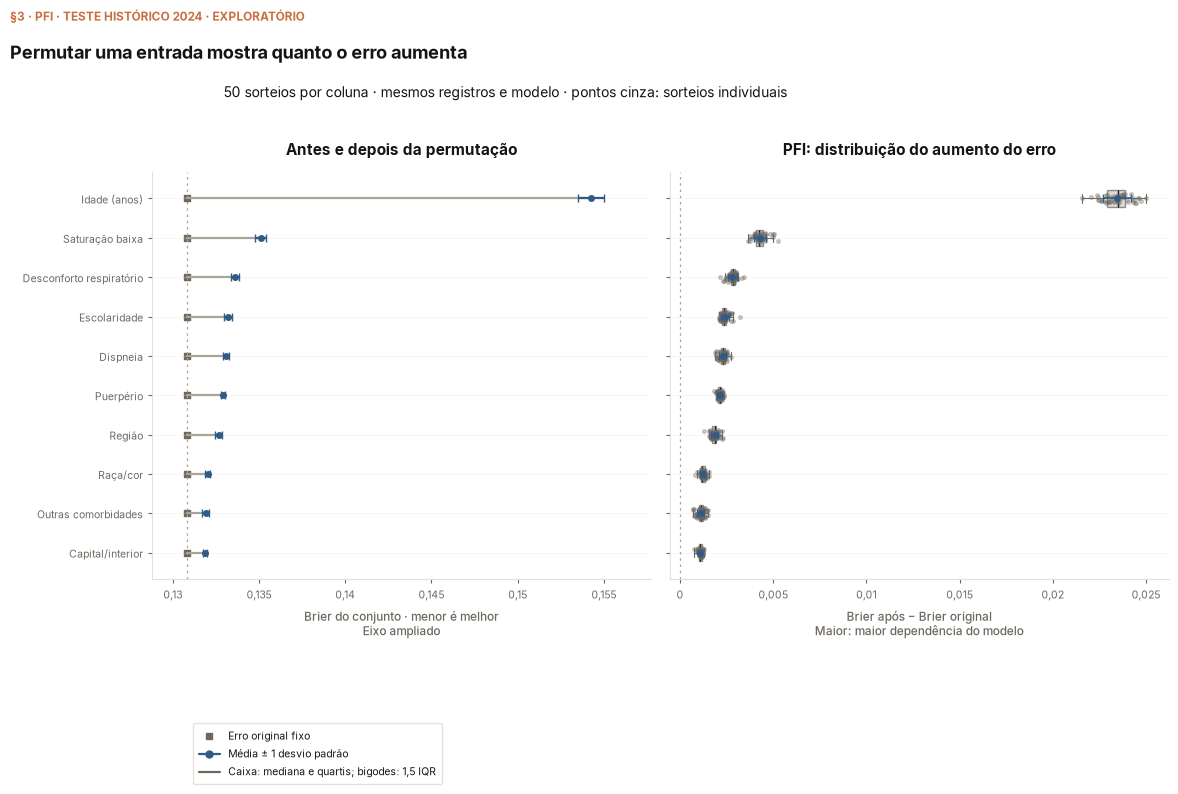

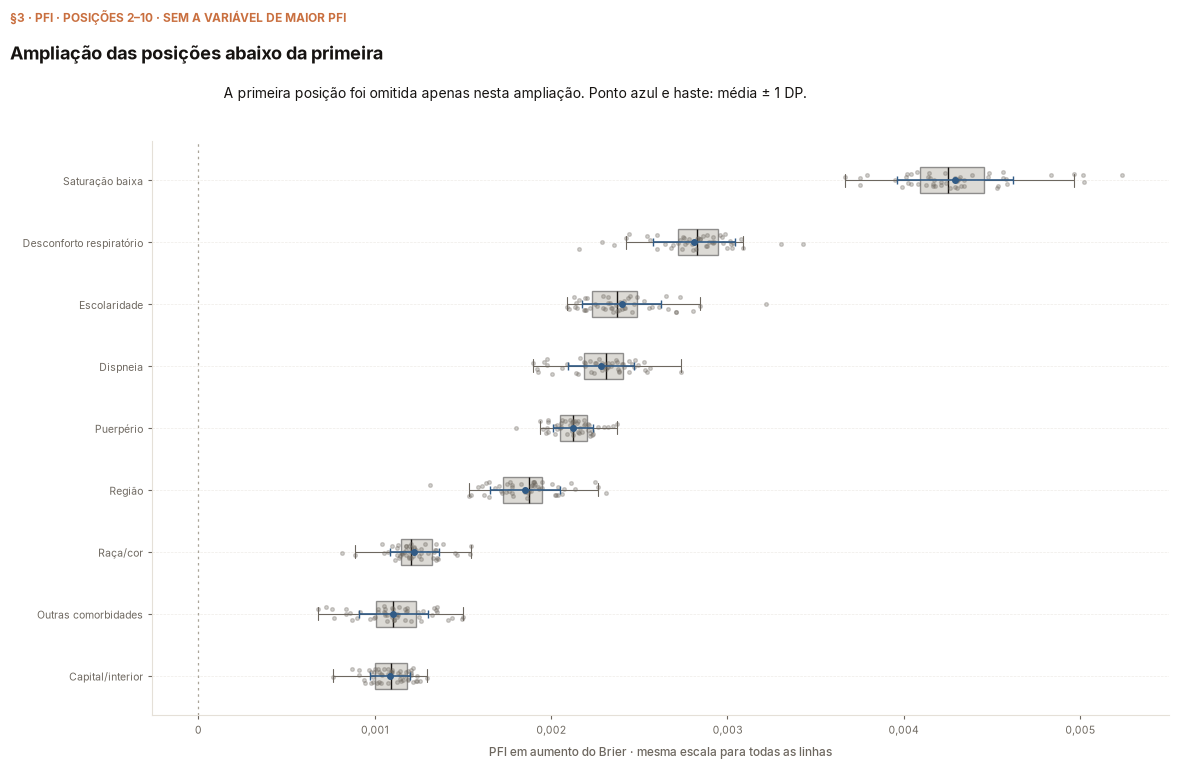

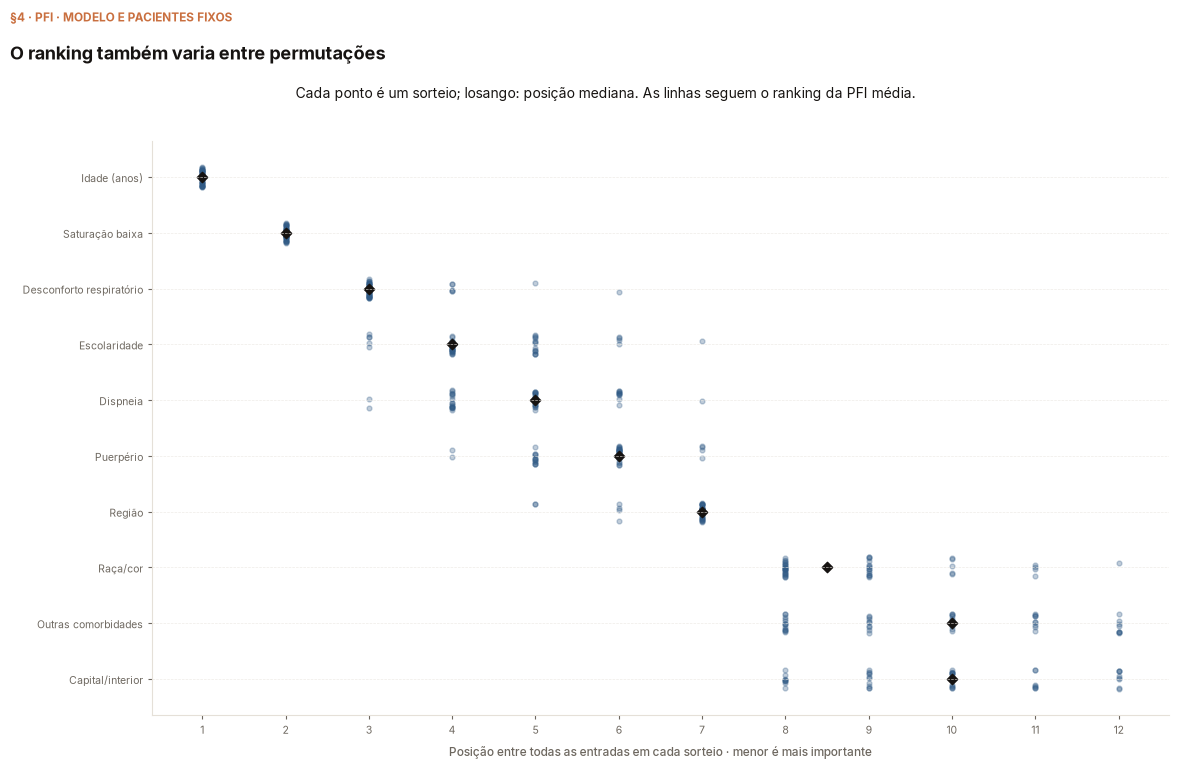

In [5]:
figures = P.figures(E, WORK / "figures_generated")
for figure in figures[:2]:
    display(figure)
    plt.close(figure)

**O que olhar.** A primeira figura permite ler o experimento inteiro; a ampliação
permite comparar diferenças menores sem confundir eixos de escalas diferentes.

## §4 — O ranking muda entre os sorteios?

Calculamos uma posição para cada entrada em cada repetição, considerando todas
as colunas. Empates recebem a posição média. O gráfico mantém as linhas ordenadas
pela PFI média; cada ponto horizontal é a posição obtida em uma repetição.
Presença entre as maiores descreve estabilidade nestes sorteios, sem medir a
probabilidade de uma posição se repetir em outra população.

        variável posição da PFI média posição mediana menor posição maior posição SD da posição fração nos dez primeiros
      idade_anos                    1        1,000000      1,000000      1,000000      0,000000                 1,000000
       saturacao                    2        2,000000      2,000000      2,000000      0,000000                 1,000000
       desc_resp                    3        3,000000      3,000000      6,000000      0,571429                 1,000000
      cs_escol_n                    4        4,000000      3,000000      7,000000      0,857143                 1,000000
        dispneia                    5        5,000000      3,000000      7,000000      0,873417                 1,000000
        puerpera                    6        6,000000      4,000000      7,000000      0,664247                 1,000000
          regiao                    7        7,000000      5,000000      7,000000      0,467734                 1,000000
         cs_raca                

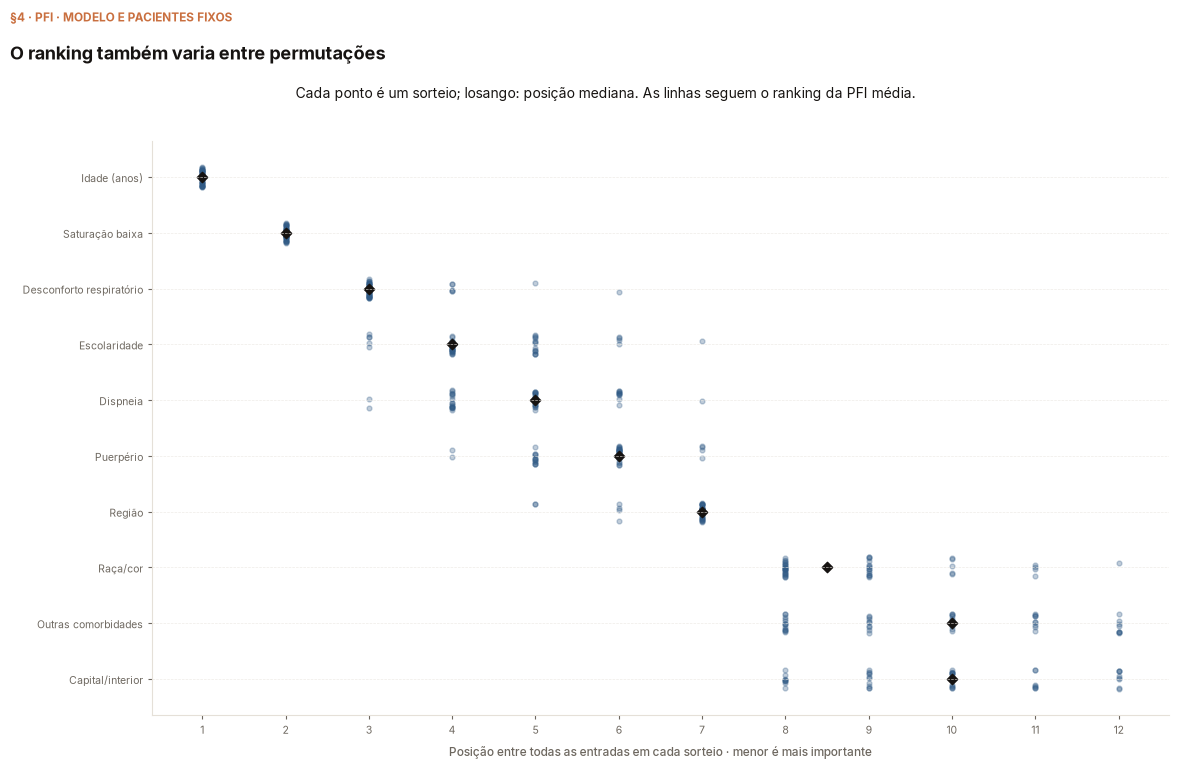

In [6]:
rank_table = pd.DataFrame([{
    "variável": r["feature"], "posição da PFI média": r["metrics"]["brier"]["rank"],
    "posição mediana": np.median(r["metrics"]["brier"]["rank_repeats"]),
    "menor posição": min(r["metrics"]["brier"]["rank_repeats"]),
    "maior posição": max(r["metrics"]["brier"]["rank_repeats"]),
    "SD da posição": r["metrics"]["brier"]["rank_sd"],
    "fração nos dez primeiros": r["metrics"]["brier"]["top10_fraction"],
} for r in rows[:10]])
print(SP.tabela(rank_table, casas=6))
display(figures[2]); plt.close(figures[2])

**O que olhar.** Uma ordem média não garante uma posição fixa em cada sorteio.
Trocas entre posições próximas não significam que o modelo foi retreinado.

## §5 — Conferir as contas e os limites

Recalculamos médias, SD e diferenças a partir dos valores individuais armazenados.
O efeito da permutação é marginal: romper uma coluna também pode romper relações
com outras entradas e produzir combinações raras ou incompatíveis com as regras
da ficha. Portanto a PFI não é uma medida causal ou de relevância clínica intrínseca.

In [7]:
max_mean_error = 0.0
max_sd_error = 0.0
for row in rows:
    for metric, summary in row["metrics"].items():
        after = np.asarray(summary["after"])
        delta = np.asarray(summary["delta"])
        direction = -1 if metric == "auc" else 1
        np.testing.assert_allclose(delta, direction * (after - E["original"][metric]), rtol=0, atol=1e-15)
        assert len(after) == protocol["repeats"]
        max_mean_error = max(max_mean_error, abs(delta.mean() - summary["mean"]))
        max_sd_error = max(max_sd_error, abs(delta.std(ddof=1) - summary["sd"]))
        assert np.isclose(after.std(ddof=1), delta.std(ddof=1))
print("Maior discrepância das médias:", SP.pt(max_mean_error, 12))
print("Maior discrepância dos SD:", SP.pt(max_sd_error, 12))
print("Colunas com previsões idênticas ao original em todos os sorteios:")
for row in rows:
    if row["identical_predictions"]:
        print(row["feature"], "PFI:", SP.pt(row["metrics"]["brier"]["mean"], 8))

Maior discrepância das médias: 0,000000000000
Maior discrepância dos SD: 0,000000000000
Colunas com previsões idênticas ao original em todos os sorteios:
meses_desde_mar2020 PFI: 0,00000000


## §6 — Síntese e vínculo com o livro

**O que o livro diz.** Molnar define a importância como a mudança de desempenho
de um modelo fixo quando uma entrada é permutada. A repetição descreve a variação
da perturbação; não incorpora, sozinha, incerteza de reamostrar pacientes,
retreinar o modelo ou transportá-lo para outro período.

Aqui “antes e depois” são erros do mesmo preditor. Não são importâncias internas
antes e depois de um novo treinamento. A importância interna por ganho usa outra
definição e outra escala, e não foi usada como a referência desta comparação.

In [8]:
winner=rows[0]; s=winner["metrics"]["brier"]
print("Maior PFI média de Brier:", winner["feature"])
print("Erro original:", SP.pt(E["original"]["brier"], 8))
print("Erro após permutar, média:", SP.pt(s["after_mean"], 8))
print("Aumento médio ± SD:", SP.pt(s["mean"], 8), "±", SP.pt(s["sd"], 8))
print("Intervalo de posições nos sorteios:", SP.pt(min(s["rank_repeats"]), 1), "a", SP.pt(max(s["rank_repeats"]), 1))
print("Leitura condicionada ao modelo atual, ao teste histórico e às permutações descritas.")

Maior PFI média de Brier: idade_anos
Erro original: 0,13080778
Erro após permutar, média: 0,15425722
Aumento médio ± SD: 0,02344944 ± 0,00073672
Intervalo de posições nos sorteios: 1,0 a 1,0
Leitura condicionada ao modelo atual, ao teste histórico e às permutações descritas.


## §7 — Exemplo conceitual para a apresentação

Fichas fictícias, desfechos construídos e uma regra escrita à mão servem apenas
para conferir a mecânica. Não são uma amostra de pacientes nem uma regra clínica.
A regra prevê óbito se a idade ultrapassa o corte ou se o campo de saturação baixa
é positivo; ignora febre. A troca ilustrativa é separada da série de sorteios.
Os dados, cada previsão e as contas impressas sustentam a primeira parte dos slides.


In [9]:
toy_age = np.array([82, 45, 67, 90, 38, 71, 29, 77])
toy_sat = np.array([0, 0, 1, 0, 0, 0, 0, 0])
toy_fever = np.array([1, 1, 0, 1, 0, 1, 1, 0])
toy_y = np.array([1, 0, 1, 1, 0, 1, 0, 1])
toy_rule = lambda age, sat: ((age >= 75) | (sat == 1)).astype(int)
toy_order = np.array([1, 0, 3, 2, 5, 7, 4, 6])
toy_original_pred = toy_rule(toy_age, toy_sat)
toy_permuted_pred = toy_rule(toy_age[toy_order], toy_sat)
toy_base = float(np.mean(toy_original_pred != toy_y))
toy_changed = float(np.mean(toy_permuted_pred != toy_y))
toy_table = pd.DataFrame({
    "ficha": list("ABCDEFGH"), "idade original": toy_age,
    "idade permutada": toy_age[toy_order], "saturação baixa": toy_sat,
    "febre": toy_fever, "óbito registrado": toy_y,
    "previsão original": toy_original_pred, "erro original": (toy_original_pred != toy_y).astype(int),
    "previsão após troca": toy_permuted_pred, "erro após troca": (toy_permuted_pred != toy_y).astype(int),
})
print("Regra didática: idade >=", SP.pt_int(75), "ou saturação baixa positiva.")
print(SP.tabela(toy_table))
print("Fichas:", SP.pt_int(len(toy_y)))
print("Erros originais:", SP.pt_int(np.sum(toy_original_pred != toy_y)), "taxa:", SP.pct(toy_base, 1))
print("Erros após a troca ilustrativa:", SP.pt_int(np.sum(toy_permuted_pred != toy_y)), "taxa:", SP.pct(toy_changed, 1))
print("Aumento nesta troca:", SP.pt((toy_changed - toy_base) * 100, 1), "p.p.")
toy_rng = np.random.default_rng(RANDOM_STATE)
toy_orders = [toy_rng.permutation(len(toy_y)) for _ in range(50)]
toy_losses = {}
for toy_name in ["Idade", "Saturação baixa", "Febre"]:
    toy_values = []
    for toy_perm in toy_orders:
        aa = toy_age[toy_perm] if toy_name == "Idade" else toy_age
        ss = toy_sat[toy_perm] if toy_name == "Saturação baixa" else toy_sat
        toy_values.append(float(np.mean(toy_rule(aa, ss) != toy_y)))
    toy_losses[toy_name] = np.asarray(toy_values)
toy_summary = pd.DataFrame([{
    "entrada": name, "erro após médio": values.mean(),
    "PFI média (p.p.)": (values.mean() - toy_base) * 100,
    "SD (p.p.)": values.std(ddof=1) * 100,
} for name, values in toy_losses.items()])
print("Sorteios por entrada:", SP.pt_int(len(toy_orders)), "semente:", SP.pt_int(RANDOM_STATE))
print(SP.tabela(toy_summary, casas=6))
print(SP.tabela(pd.DataFrame({"sorteio": np.arange(1, 51), "erro após permutar idade": toy_losses["Idade"]}), casas=6))
assert np.sum(toy_original_pred != toy_y) == 1
assert np.sum(toy_permuted_pred != toy_y) == 4
assert np.array_equal(np.sort(toy_age), np.sort(toy_age[toy_order]))
assert np.all(toy_losses["Febre"] == toy_base)


Regra didática: idade >= 75 ou saturação baixa positiva.
ficha idade original idade permutada saturação baixa febre óbito registrado previsão original erro original previsão após troca erro após troca
    A             82              45               0     1                1                 1             0                   0               1
    B             45              82               0     1                0                 0             0                   1               1
    C             67              90               1     0                1                 1             0                   1               0
    D             90              67               0     1                1                 1             0                   0               1
    E             38              71               0     0                0                 0             0                   0               0
    F             71              77               0     1                1    

## §8 — Premissas numéricas da aula de Sebastian Raschka

A apresentação interativa acompanha a sequência da [aula conceitual de Raschka](https://www.youtube.com/watch?v=VUvShOEFdQo).
A célula registra valores **ilustrativos fornecidos pelo autor**, sem tratá-los como resultados do nosso modelo ou como acurácias calculadas a partir do pequeno esquema de linhas.
A matriz desenhada explica a permutação; as acurácias ilustram a comparação no conjunto de avaliação.
O [caderno público do autor](https://github.com/rasbt/stat451-machine-learning-fs21/blob/main/13-feature-selection/05_permutation-importance.ipynb) fornece o gráfico de vinhos e sua dispersão.

**Nossa contribuição didática.** Separar a operação na matriz da conta do desempenho, manter modelo e desfechos fixos e distinguir a diferença isolada da média de repetições.
As ressalvas sobre avaliação fora do treino e entradas dependentes seguem [Molnar, capítulo de PFI](https://christophm.github.io/interpretable-ml-book/feature-importance.html).

In [10]:
video_values = np.array([1.4, 1.1, -0.1, 2.2])
video_order = np.array([1, 2, 3, 0])
video_y = np.array([0, 2, 1, 0])
video_base = 0.99
video_after = 0.85
video_drops = np.array([0.14, 0.05, 0.21])
print("Premissas ilustrativas fornecidas na aula de Sebastian Raschka; não são resultados SRAG.")
print(SP.tabela(pd.DataFrame({"coluna original": video_values,
    "coluna permutada": video_values[video_order], "desfecho fixo": video_y}), casas=1))
print("Linhas no esquema:", SP.pt_int(len(video_y)))
print("Colunas de entradas no esquema:", SP.pt_int(3))
print("Acurácia original do exemplo:", SP.pct(video_base, 0))
print("Acurácia após permutar no exemplo:", SP.pct(video_after, 0))
print("Diferença:", SP.pt(video_base - video_after, 2),
      "ou", SP.pt((video_base - video_after) * 100, 0), "pontos percentuais")
print("Número de repetições sugerido na aula:", SP.pt_int(50))
print(SP.tabela(pd.DataFrame({"entrada": np.arange(1, 4),
    "queda ilustrativa": video_drops, "queda (p.p.)": video_drops * 100,
    "acurácia após ilustrativa": video_base - video_drops}), casas=2))
print("Ordem ilustrativa das entradas:", ", ".join(SP.pt_int(i) for i in np.argsort(video_drops)[::-1] + 1))
print("No caderno do autor: np.std(imp_all, axis=1), com ddof padrão igual a", SP.pt_int(0))
assert np.array_equal(np.sort(video_values), np.sort(video_values[video_order]))
assert np.isclose(video_base - video_after, video_drops[0])

Premissas ilustrativas fornecidas na aula de Sebastian Raschka; não são resultados SRAG.
coluna original coluna permutada desfecho fixo
            1,4              1,1             0
            1,1             -0,1             2
           -0,1              2,2             1
            2,2              1,4             0
Linhas no esquema: 4
Colunas de entradas no esquema: 3
Acurácia original do exemplo: 99%
Acurácia após permutar no exemplo: 85%
Diferença: 0,14 ou 14 pontos percentuais
Número de repetições sugerido na aula: 50
entrada queda ilustrativa queda (p.p.) acurácia após ilustrativa
      1              0,14        14,00                      0,85
      2              0,05         5,00                      0,94
      3              0,21        21,00                      0,78
Ordem ilustrativa das entradas: 3, 1, 2
No caderno do autor: np.std(imp_all, axis=1), com ddof padrão igual a 0


Fontes: [Molnar — Permutation Feature Importance](https://christophm.github.io/interpretable-ml-book/feature-importance.html) ·
[scikit-learn — permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

## §9 — Diferença e razão do mesmo erro

[Molnar](https://christophm.github.io/interpretable-ml-book/feature-importance.html)
define PFI como diferença ou razão do erro de um modelo fixo. A referência
positiva é comum às variáveis, portanto a ordem das médias é preservada.
As hastes mostram SD entre permutações, condicionado ao modelo e ao teste.

O modelo do curso é reconstruído e seu Brier completo é conferido.
O recorte contém oito fichas adultas reais: as primeiras quatro elegíveis por
desfecho, reunidas na ordem original do teste. A seleção usa o desfecho, sem filtro
por previsão. Serve para mostrar a operação; não estima acurácia, prevalência
nem importância. A regra aparece no código e no resumo exportado.
Idade e saturação são trocadas em rodadas separadas, cada uma partindo do original.
Acerto de classe usa um limiar didático; Brier usa probabilidades contínuas.

As equações LaTeX, gráficos em inglês e dados da apresentação são exportados
à área temporária de figuras para promoção explícita.


Comparação SRAG: diferenças e razões do erro de Brier; média e SD amostral.
         feature                 label     before after_mean   after_sd difference_mean difference_sd ratio_mean   ratio_sd relative_increase_percent
      idade_anos                   Age 0,13080778 0,15425722 0,00073672      0,02344944    0,00073672 1,17926637 0,00563205               17,92663726
       saturacao Low oxygen saturation 0,13080778 0,13509785 0,00032827      0,00429007    0,00032827 1,03279675 0,00250955                3,27967477
       desc_resp  Respiratory distress 0,13080778 0,13361822 0,00023345      0,00281044    0,00023345 1,02148525 0,00178472                2,14852481
      cs_escol_n             Education 0,13080778 0,13320743 0,00022399      0,00239965    0,00022399 1,01834488 0,00171238                1,83448789
        dispneia               Dyspnea 0,13080778 0,13309244 0,00018807      0,00228466    0,00018807 1,01746581 0,00143776                1,74658066
        puerpera     Pos

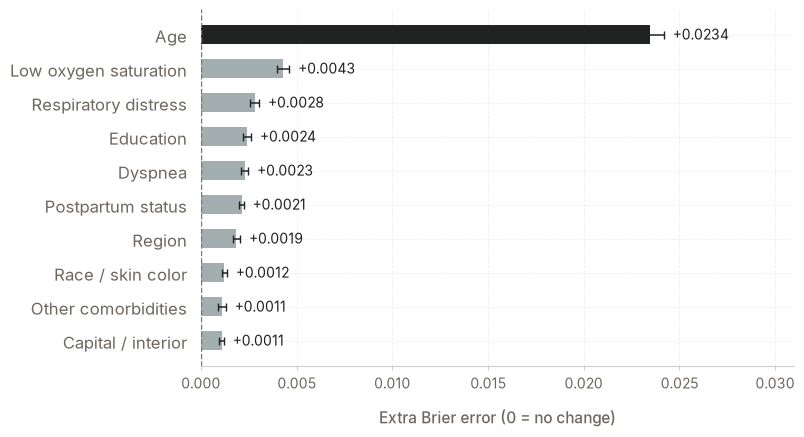

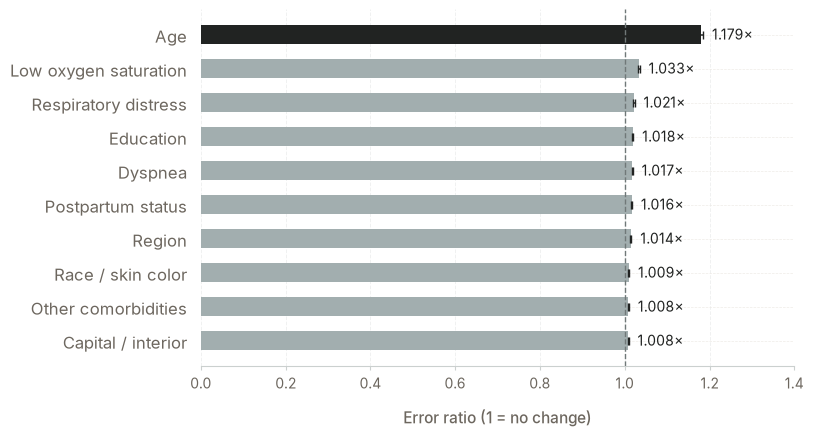

Brier reconstruído no teste completo: 0,13080778
Regra do recorte: primeiras quatro fichas adultas de cada desfecho no teste, mantida a ordem original.
Registros por desfecho no recorte: 4
Registros exibidos: 8
Erros de classe originais no recorte: 4
O recorte foi selecionado pelo desfecho para ensinar a operação, não para medir o desempenho.
Limiar didático de classificação: 0,50
idade_anos: dias entre nascimento e início dos sintomas, divididos por 365,25
Valores reais do recorte e previsões do modelo fixo:
record  idade_anos saturacao y_obito p_original class_original  correct_original brier_original p_after_age class_after_age  correct_after_age brier_after_age p_after_oxygen class_after_oxygen  correct_after_oxygen brier_after_oxygen
     A 76,66255951       sim       0 0,38593900              0              True     0,14894891  0,39774379               0               True      0,15820012     0,38593900                  0                  True         0,14894891
     B 80,8651580

15856

In [11]:
baseline = float(E["original"]["brier"])
if baseline <= 0:
    raise ValueError("A razão requer erro original positivo.")
slide_rows = sorted(E["rows"], key=lambda r: r["metrics"]["brier"]["rank"])[:10]
english_labels = {
    "idade_anos": "Age",
    "saturacao": "Low oxygen saturation",
    "desc_resp": "Respiratory distress",
    "cs_escol_n": "Education",
    "dispneia": "Dyspnea",
    "puerpera": "Postpartum status",
    "regiao": "Region",
    "cs_raca": "Race / skin color",
    "out_morbi": "Other comorbidities",
    "capital_interior": "Capital / interior",
}
scales = []
for r in slide_rows:
    after = np.asarray(r["metrics"]["brier"]["after"], dtype=float)
    diff = after - baseline
    ratio = after / baseline
    scales.append({
        "feature": r["feature"], "label": english_labels[r["feature"]],
        "before": baseline, "after_mean": float(after.mean()),
        "after_sd": float(after.std(ddof=1)),
        "difference_mean": float(diff.mean()), "difference_sd": float(diff.std(ddof=1)),
        "ratio_mean": float(ratio.mean()), "ratio_sd": float(ratio.std(ddof=1)),
        "relative_increase_percent": float((ratio.mean() - 1) * 100),
    })
scale_table = pd.DataFrame(scales)
print("Comparação SRAG: diferenças e razões do erro de Brier; média e SD amostral.")
print(SP.tabela(scale_table, casas=8))
print("Ponto neutro, diferença:", SP.pt(0, 0))
print("Ponto neutro, razão:", SP.pt(1, 0))
print("Ordenação igual nas duas escalas:", bool(np.array_equal(
    np.argsort(-scale_table["difference_mean"].to_numpy()),
    np.argsort(-scale_table["ratio_mean"].to_numpy()))))

slide_dir = WORK / "figures_generated"
slide_dir.mkdir(exist_ok=True)
plt.rcParams["svg.fonttype"] = "none"
for mode, neutral, xmax, xlabel in [
    ("difference", 0, 0.031, "Extra Brier error (0 = no change)"),
    ("ratio", 1, 1.40, "Error ratio (1 = no change)"),
]:
    means = scale_table[mode + "_mean"].to_numpy()
    sds = scale_table[mode + "_sd"].to_numpy()
    positions = np.arange(len(scales))
    fig, ax = plt.subplots(figsize=(8.6, 4.3))
    colors = ["#212322"] + ["#a2aeaf"] * (len(scales) - 1)
    ax.barh(positions, means, left=0, height=.54, color=colors)
    for k, (mean, sd) in enumerate(zip(means, sds)):
        ax.errorbar(mean, k, xerr=sd, fmt="none", ecolor="#212322", capsize=3, elinewidth=1.1)
        value_label = f"+{mean:.4f}" if mode == "difference" else f"{mean:.3f}×"
        ax.text(mean + sd + xmax * .015, k, value_label, va="center", ha="left",
                fontsize=10, color="#212322", gid=f"pfi-value-{k}")
    ax.set_yticks(positions, scale_table["label"], fontsize=12)
    ax.invert_yaxis()
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel, fontsize=11, labelpad=12)
    ax.axvline(neutral, color="#707878", lw=1, ls="--")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cbd0cf")
    ax.tick_params(axis="y", length=0, pad=10)
    ax.tick_params(axis="x", labelsize=10, color="#cbd0cf")
    ax.xaxis.grid(True, color="#eceded", lw=.7)
    ax.set_axisbelow(True)
    fig.subplots_adjust(left=.29, right=.98, top=.98, bottom=.15)
    fig.savefig(slide_dir / ("pfi-slide-" + mode + ".svg"), facecolor="white")
    fig.savefig(slide_dir / ("pfi-slide-" + mode + ".png"), dpi=180, facecolor="white")
    display(fig)
    plt.close(fig)
# Reconstruct the exact course reference to obtain real row-level predictions.
reference_gold = P.M.load_gold()
reference_x, _, reference_y = P.M.design_matrix(reference_gold)
train_mask = (reference_gold["split"] == "train").to_numpy()
test_mask = (reference_gold["split"] == "test").to_numpy()
preview_model = P.XGBClassifier(**E["protocol"]["xgb_params"]).fit(reference_x.loc[train_mask], reference_y[train_mask])
reference_probability = preview_model.predict_proba(reference_x.loc[test_mask])[:, 1]
reconstructed_brier = P.scores(reference_y[test_mask], reference_probability)["brier"]
assert np.isclose(reconstructed_brier, baseline, atol=1e-8, rtol=0)
print("Brier reconstruído no teste completo:", SP.pt(reconstructed_brier, 8))
threshold = 0.5
evaluation = reference_gold.loc[test_mask].copy()
evaluation["p_original"] = reference_probability
# Retain the original eight adult records: first eligible rows by outcome, then original order.
preview_parts = [evaluation[(evaluation["idade_anos"] >= 18) &
    (evaluation["y_obito"] == outcome)].head(4) for outcome in [0, 1]]
preview_index = pd.concat(preview_parts).sort_index().index
preview = reference_gold.loc[preview_index, ["idade_anos", "saturacao", "y_obito"]].reset_index(drop=True)
preview_x = reference_x.loc[preview_index].reset_index(drop=True)
original_probability = preview_model.predict_proba(preview_x)[:, 1]
original_class = (original_probability >= threshold).astype(int)
# The recorded teaching permutation, reused separately for each column.
preview_order = np.array([1, 0, 3, 2, 5, 7, 4, 6])
assert np.array_equal(np.sort(preview_order), np.arange(len(preview)))
print("Regra do recorte: primeiras quatro fichas adultas de cada desfecho no teste, mantida a ordem original.")
print("Registros por desfecho no recorte:", SP.pt_int(4))
print("Registros exibidos:", SP.pt_int(len(preview)))
print("Erros de classe originais no recorte:", SP.pt_int(np.sum(original_class != preview["y_obito"].to_numpy())))
print("O recorte foi selecionado pelo desfecho para ensinar a operação, não para medir o desempenho.")
print("Limiar didático de classificação:", SP.pt(threshold, 2))
print("idade_anos: dias entre nascimento e início dos sintomas, divididos por", SP.pt(365.25, 2))
preview_table = preview.copy()
preview_table.insert(0, "record", list("ABCDEFGH"))
preview_table["p_original"] = original_probability.astype(float)
preview_table["class_original"] = original_class
preview_table["correct_original"] = original_class == preview["y_obito"].to_numpy()
preview_table["brier_original"] = (original_probability.astype(float) - preview["y_obito"].to_numpy()) ** 2
rounds = []
for feature, label, cell in [("idade_anos", "Age", "age"), ("saturacao", "Low oxygen", "oxygen")]:
    changed = preview_x.copy()
    changed[feature] = preview_x[feature].iloc[preview_order].set_axis(changed.index)
    assert all(changed[col].equals(preview_x[col]) for col in preview_x if col != feature)
    probability = preview_model.predict_proba(changed)[:, 1]
    predicted = (probability >= threshold).astype(int)
    individual_brier = (probability.astype(float) - preview["y_obito"].to_numpy()) ** 2
    assert np.array_equal(np.round(probability, 4) >= threshold, predicted.astype(bool))
    preview_table["p_after_" + cell] = probability.astype(float)
    preview_table["class_after_" + cell] = predicted
    preview_table["correct_after_" + cell] = predicted == preview["y_obito"].to_numpy()
    preview_table["brier_after_" + cell] = individual_brier
    rounds.append({"feature": feature, "label": label, "cell": cell,
        "values": preview_x[feature].tolist(),
        "probability": probability.astype(float).tolist(), "predicted": predicted.tolist(),
        "correct": (predicted == preview["y_obito"].to_numpy()).tolist(),
        "individual_brier": individual_brier.tolist(),
        "sample_brier_mean": float(individual_brier.mean()),
        "full_test": next(r for r in scales if r["feature"] == feature)})
print("Valores reais do recorte e previsões do modelo fixo:")
print(SP.tabela(preview_table, casas=8))
print("Brier médio original apenas no recorte:", SP.pt(preview_table["brier_original"].mean(), 8))
for round_data in rounds:
    print("Brier médio após trocar", round_data["label"], "apenas no recorte:", SP.pt(round_data["sample_brier_mean"], 8))
    print("Erros de classe após trocar", round_data["label"], "no recorte:", SP.pt_int(np.count_nonzero(~np.asarray(round_data["correct"], dtype=bool))))
print("Os gráficos desta aula usam o teste temporal completo do estudo, não este recorte selecionado.")
# LaTeX equations rendered as self-contained SVG paths, without a PDF dependency.
equations = {
    "difference": r"$FI_j = e_{\mathrm{perm},j} - e_{\mathrm{orig}}$",
    "ratio": r"$FI_j = \frac{e_{\mathrm{perm},j}}{e_{\mathrm{orig}}}$",
    "brier": r"$\mathrm{Brier} = \frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2$",
}
with plt.rc_context({"mathtext.fontset": "cm", "svg.fonttype": "path"}):
    for name, equation in equations.items():
        fig = plt.figure(figsize=(5, .8))
        fig.text(.02, .5, equation, va="center", ha="left", fontsize=24, color="#212322")
        fig.savefig(slide_dir / ("equation-" + name + ".svg"), transparent=True, bbox_inches="tight", pad_inches=.05)
        plt.close(fig)
summary = {"protocol": E["protocol"], "original": E["original"], "rows": scales,
    "equations": equations,
    "preview": {"rows": preview_table.to_dict(orient="records"), "rounds": rounds,
        "permutation": preview_order.tolist(), "threshold": threshold,
        "age_unit": "decimal years at symptom onset",
        "selection": {"records_per_outcome": 4, "rule": "First four adult records per outcome in the temporal test, then original dataset order. Outcome-selected teaching subset, not a performance sample."},
        "scope": "Eight real SRAG records selected by outcome to illustrate the operation. Separate age and low-oxygen swaps; restore original inputs before each. Full-study importance is computed on the full temporal test set."}}
(slide_dir / "pfi-slide-data.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))


## §11 — Coerência entre slides e código executável

A conferência usa os valores completos, antes do arredondamento. O mesmo erro
original e as mesmas médias e SD alimentam a animação e o ranking. O recorte
didático é uma avaliação distinta do teste completo. O exemplo executável
repete a PFI de idade com o mesmo modelo, registros e ordens do experimento.

Raschka apresenta acurácia, com perda de desempenho igual à referência menos
o resultado permutado. Com Brier, o aumento do erro inverte essa ordem.
[Molnar](https://christophm.github.io/interpretable-ml-book/feature-importance.html)
usa a mudança de perda para interpretar a dependência preditiva do modelo.


Coerência: números globais da animação e do ranking são idênticos antes do arredondamento.
Erro máximo entre as repetições do código didático e o registro: 0,000000000000
Traço de cada repetição exposta pela animação: erro permutado, diferença, média e SD acumulados (SD indefinida na primeira).
repeat original_brier permuted_brier difference running_mean running_sd
     1     0,13080778     0,15357206 0,02276428   0,02276428         NA
     2     0,13080778     0,15512181 0,02431404   0,02353916 0,00109584
     3     0,13080778     0,15511792 0,02431014   0,02379615 0,00089363
     4     0,13080778     0,15476658 0,02395880   0,02383681 0,00073416
     5     0,13080778     0,15460160 0,02379382   0,02382822 0,00063610
     6     0,13080778     0,15527176 0,02446398   0,02393418 0,00062535
     7     0,13080778     0,15395809 0,02315031   0,02382220 0,00064317
     8     0,13080778     0,15555497 0,02474719   0,02393782 0,00067935
     9     0,13080778     0,15447597 0,02366819   0,0239

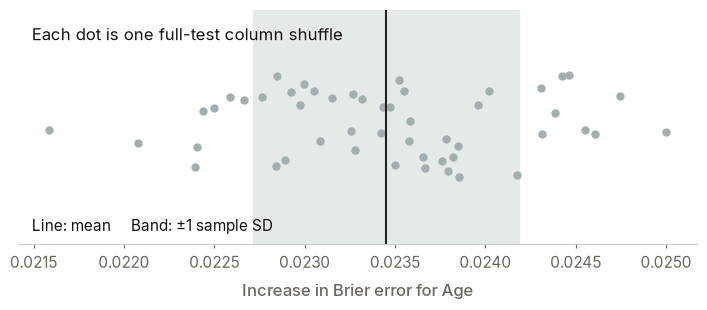

In [12]:
import importlib.util
walkthrough_spec = importlib.util.spec_from_file_location("srag_pfi_walkthrough", REPO / "tools" / "srag_pfi_walkthrough.py")
walkthrough = importlib.util.module_from_spec(walkthrough_spec)
walkthrough_spec.loader.exec_module(walkthrough)
xe = reference_x.loc[test_mask].reset_index(drop=True)
ye = reference_y[test_mask]
rng = np.random.default_rng(E["protocol"]["permutation_seed"])
orders = [rng.permutation(len(xe)) for _ in range(E["protocol"]["repeats"])]
trace_before, trace_after = walkthrough.trace_feature(preview_model, xe, ye, "idade_anos", orders)
age_record = next(row for row in E["rows"] if row["feature"] == "idade_anos")
recorded_after = np.asarray(age_record["metrics"]["brier"]["after"])
np.testing.assert_allclose(trace_after, recorded_after, atol=1e-10, rtol=0)
np.testing.assert_allclose(trace_before, baseline, atol=1e-10, rtol=0)
for round_data in summary["preview"]["rounds"]:
    canonical = next(row for row in summary["rows"] if row["feature"] == round_data["feature"])
    assert round_data["full_test"] == canonical
for row in summary["rows"]:
    np.testing.assert_allclose(row["difference_mean"], row["after_mean"] - baseline, atol=1e-15)
    np.testing.assert_allclose(row["ratio_mean"], row["after_mean"] / baseline, atol=1e-15)
print("Coerência: números globais da animação e do ranking são idênticos antes do arredondamento.")
print("Erro máximo entre as repetições do código didático e o registro:", SP.pt(float(np.max(np.abs(trace_after - recorded_after))), 12))
trace_delta = trace_after - trace_before
# Every running value exposed by the code animation is printed here.
repeat_audit = pd.DataFrame({
    "repeat": np.arange(1, len(trace_after) + 1),
    "original_brier": trace_before,
    "permuted_brier": trace_after,
    "difference": trace_delta,
    "running_mean": [trace_delta[:k].mean() for k in range(1, len(trace_delta) + 1)],
    "running_sd": [np.nan if k == 1 else trace_delta[:k].std(ddof=1) for k in range(1, len(trace_delta) + 1)],
})
print("Traço de cada repetição exposta pela animação: erro permutado, diferença, média e SD acumulados (SD indefinida na primeira).")
print(SP.tabela(repeat_audit, casas=8))
print("A quantidade de repetições é escolha do protocolo, não um requisito universal nem prova de convergência:", len(trace_after))
print("Primeira repetição de idade: Brier original, permutado e diferença:", SP.pt(trace_before, 8), SP.pt(trace_after[0], 8), SP.pt(trace_delta[0], 8))
print("Média das repetições de idade: Brier permutado e diferença:", SP.pt(trace_after.mean(), 8), SP.pt(trace_delta.mean(), 8))
print("SD da diferença de idade:", SP.pt(trace_delta.std(ddof=1), 8))
print("Recorte didático, média de Brier original:", SP.pt(preview_table["brier_original"].mean(), 8))
print("Recorte didático, média de Brier com idade permutada:", SP.pt(preview_table["brier_after_age"].mean(), 8))
print("As médias do recorte didático não estimam a PFI do teste completo.")
print("Configuração temporal da aula: treino até 2022; validação 2023; teste", E["protocol"]["period"])
summary["walkthrough"] = {"feature": "idade_anos", "after": trace_after.tolist(), "difference": trace_delta.tolist(),
    "first_after": float(trace_after[0]), "first_difference": float(trace_delta[0]),
    "mean_after": float(trace_after.mean()), "mean_difference": float(trace_delta.mean()), "sd_difference": float(trace_delta.std(ddof=1)),
    "train_end": 2022, "validation_year": 2023,
    "audit": "global values in slides 2, 3 and the code summary are identical before rounding",
    "max_trace_error": float(np.max(np.abs(trace_after - recorded_after)))}
(slide_dir / "pfi-slide-data.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
# A scientific plot of measured repeat values. Vertical offsets only separate dots visually.
with plt.rc_context({"svg.fonttype": "none"}):
    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    offsets = np.random.default_rng(42).uniform(-.14, .14, len(trace_delta))
    for k, (delta, offset) in enumerate(zip(trace_delta, offsets)):
        ax.plot(delta, offset, "o", color="#a2aeaf", markersize=5, gid=f"repeat-point-{k}")
    mean = trace_delta.mean()
    sd = trace_delta.std(ddof=1)
    ax.axvspan(mean-sd, mean+sd, color="#e5eae8", zorder=0, gid="repeat-sd")
    ax.axvline(mean, color="#212322", lw=1.5, gid="repeat-mean")
    ax.set_xlabel("Increase in Brier error for Age", fontsize=12)
    ax.set_yticks([])
    ax.set_ylim(-.3, .3)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cbd0cf")
    ax.tick_params(axis="x", labelsize=11)
    ax.text(.02, .94, "Each dot is one full-test column shuffle", transform=ax.transAxes, fontsize=12, va="top")
    ax.text(.02, .04, "Line: mean     Band: ±1 sample SD", transform=ax.transAxes, fontsize=11, va="bottom")
    fig.tight_layout()
    fig.savefig(slide_dir / "pfi-age-repeats.svg", facecolor="white")
    fig.savefig(slide_dir / "pfi-age-repeats.png", dpi=180, facecolor="white")
    display(fig)
    plt.close(fig)


## §13 — Do dado ao modelo escolhido

Estas células leem os cards comprometidos, não repetem a busca de modelos. A escolha usa somente validação; o teste histórico já observado serve à explicação exploratória.


In [13]:
counts = json.loads((REPO / "modules/00-dataset/gold/counts.json").read_text())
selection = json.loads((REPO / "modules/00-dataset/gold/selection_metrics.json").read_text())
model_card = json.loads((REPO / "modules/00-dataset/gold/model_metrics.json").read_text())
labels = {"dummy": "Prevalence baseline", "lpm": "Linear probability model", "logit": "Logistic regression", "arvore": "Decision tree", "floresta": "Random forest", "xgb": "XGBoost"}
scoreboard = [{"model": r["modelo"], "label": labels[r["modelo"]], "auc": r["auc"], "brier": r["brier"]} for r in selection["placar"] if r["split"] == "val"]
assert selection["escolha"]["vencedor"] == "xgb"
assert max(scoreboard, key=lambda r: r["auc"])["model"] == "xgb"
assert selection["escolha"]["melhores"]["xgb"].items() <= E["protocol"]["xgb_params"].items()
assert selection["amostra"]["treino"] == int(train_mask.sum()) == E["protocol"]["n_train"]
assert counts["splits"]["test"]["n"] == len(xe) == E["protocol"]["n_evaluation"]
assert len(reference_x.columns) == len(E["protocol"]["features"])
assert np.isclose(next(r for r in model_card["xgb"] if r["split"] == "test")["brier"], baseline, atol=5e-5)
study = {
    "cohort_n": counts["n_gold"], "train_sample_n": int(train_mask.sum()),
    "input_n": len(reference_x.columns), "train_end": 2022, "validation_year": 2023, "test_year": 2024,
    "splits": counts["splits"], "sample_seed": 42, "scoreboard": scoreboard,
    "search_counts": {key: len(value) for key, value in selection["buscas"].items()},
    "bootstrap_repeats": selection["bootstrap"][0]["reamostras"],
    "winner": selection["escolha"]["vencedor"], "xgb_params": E["protocol"]["xgb_params"],
    "test_auc": E["original"]["auc"], "test_brier": baseline,
    "selection_rule": "Highest 2023 validation AUC; paired-bootstrap one-SE technical tie rule; calibration gap, parsimony, determinism as tie breakers. No tie occurred. Test excluded from selection.",
    "cohort_rule": "Hospitalized, broad COVID definition, closed outcomes, symptom onset from 2020-02-26, age present and at most 120 years; displaced rows excluded.",
    "balancing": "No class weights or resampling in the reference. Separate balancing comparison did not replace it.",
    "missing": "Unknown categorical values retained as explicit categories; they are not recoded as no. XGBoost uses native categorical inputs.",
    "status": E["protocol"]["status"],
}
print("Proveniência: Bronze (fonte preservada), Silver (tipos/domínios/datas), Gold (coorte, alvo e partições).")
print("Regra da coorte:", study["cohort_rule"])
print("Registros Gold:", SP.pt_int(study["cohort_n"]))
print("Amostra uniforme de treino:", SP.pt_int(study["train_sample_n"]), "; semente:", SP.pt_int(study["sample_seed"]))
print("Entradas do modelo:", SP.pt_int(study["input_n"]))
print("Treino até", study["train_end"], "; validação", study["validation_year"], "; teste", study["test_year"])
print(SP.tabela(pd.DataFrame(study["splits"]).T.reset_index(names="split"), casas=4))
print("Melhores candidatos por família, métricas de validação registradas no card (não refeitas nesta seção):")
print(SP.tabela(pd.DataFrame(scoreboard), casas=4))
print("Configurações pesquisadas por família:", study["search_counts"])
print("Total de configurações:", sum(study["search_counts"].values()), "; famílias:", len(scoreboard))
print("Reamostras bootstrap pareadas para desempate:", study["bootstrap_repeats"])
print("Escolha registrada:", selection["escolha"]["log"])
print("Parâmetros do XGBoost fixo:", study["xgb_params"])
print("AUC teste:", SP.pt(study["test_auc"], 4), "; Brier teste:", SP.pt(study["test_brier"], 8))
summary["study"] = study
(slide_dir / "pfi-slide-data.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")


Proveniência: Bronze (fonte preservada), Silver (tipos/domínios/datas), Gold (coorte, alvo e partições).
Regra da coorte: Hospitalized, broad COVID definition, closed outcomes, symptom onset from 2020-02-26, age present and at most 120 years; displaced rows excluded.
Registros Gold: 1.282.970
Amostra uniforme de treino: 200.000 ; semente: 42
Entradas do modelo: 40
Treino até 2022 ; validação 2023 ; teste 2024
split letalidade_pct              n       obitos
 test        18,2000    16.142,0000   2.945,0000
train        31,4000 1.242.680,0000 390.769,0000
  val        18,9000    24.148,0000   4.572,0000
Melhores candidatos por família, métricas de validação registradas no card (não refeitas nesta seção):
   model                    label    auc  brier
   dummy      Prevalence baseline 0,5000 0,1689
     lpm Linear probability model 0,7232 0,1552
   logit      Logistic regression 0,7214 0,1545
  arvore            Decision tree 0,7041 0,1434
floresta            Random forest 0,7403 0,1454


21630

## §14 — Dependência nos dados: cardiopatia e diabetes

Medimos associação nominal no teste completo, distinguindo os registros desconhecidos. Comparamos a PFI marginal registrada com dois diagnósticos adicionais no mesmo modelo: permutação conjunta e permutação dentro de subgrupos de diabetes. Não há retreino nem seleção de outro modelo. As perguntas são diferentes e não constituem uma competição por uma importância “verdadeira”.

[Molnar: dependência e subgrupos](https://christophm.github.io/interpretable-ml-book/feature-importance.html) · [SciPy: associação nominal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html)


Teste temporal: cardiopatia (linhas) × diabetes (colunas), registros reais processados:
  cardiopati desconhecido   nao   sim
desconhecido        6.859     8   387
         nao           10 2.674   818
         sim        1.116 2.248 2.022
V de Cramér com desconhecidos: 0,61093605
V de Cramér apenas sim/não: 0,24713795 ; n: 7.762
Desconhecido em ambos: 6.859
V mede associação nominal, não correlação de Pearson nem relação causal. A comparação dos recortes é descritiva.


Abordagem por subgrupos de Molnar: separar por diabetes, permutar cardiopatia somente dentro de cada subgrupo, prever com o mesmo modelo e comparar os erros do próprio grupo; repetir.
       level     n     before first_after after_mean difference_mean difference_sd
desconhecido 7.985 0,09476484  0,09488512 0,09479271      0,00002788    0,00005532
         nao 4.930 0,16218730  0,16237015 0,16228765      0,00010034    0,00011581
         sim 3.227 0,17205409  0,17232341 0,17211873      0,00006465    0,00016679
Gráfico didático de subgrupos, Brier × 1000:
       group     n mean_plot sd_plot
desconhecido 7.985     0,028   0,055
         nao 4.930     0,100   0,116
         sim 3.227     0,065   0,167
Agregação adicional nesta aula: média dos erros de cada grupo ponderada por seu tamanho; coincide com erro no teste completo em todas as repetições.
Diagnóstico exploratório, mesmo XGBoost, teste e Brier; médias e SD amostrais de 50 permutações:
       key                         label     

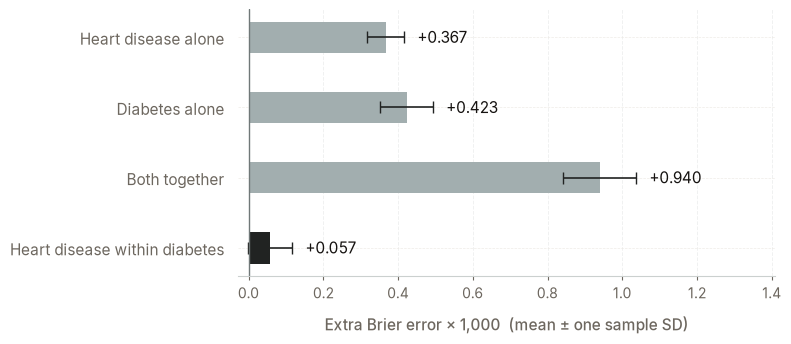

In [14]:
from scipy.stats.contingency import association

pair = ["cardiopati", "diabetes"]
levels = ["desconhecido", "nao", "sim"]
def pair_counts(matrix):
    return pd.crosstab(matrix[pair[0]], matrix[pair[1]]).reindex(index=levels, columns=levels, fill_value=0)

original_pair = pair_counts(xe)
known_pair = original_pair.loc[["nao", "sim"], ["nao", "sim"]]
v_all = float(association(original_pair.to_numpy(), method="cramer", correction=False))
v_known = float(association(known_pair.to_numpy(), method="cramer", correction=False))
print("Teste temporal: cardiopatia (linhas) × diabetes (colunas), registros reais processados:")
print(SP.tabela(original_pair.reset_index(), casas=0))
print("V de Cramér com desconhecidos:", SP.pt(v_all, 8))
print("V de Cramér apenas sim/não:", SP.pt(v_known, 8), "; n:", SP.pt_int(known_pair.to_numpy().sum()))
print("Desconhecido em ambos:", SP.pt_int(original_pair.loc["desconhecido", "desconhecido"]))
print("V mede associação nominal, não correlação de Pearson nem relação causal. A comparação dos recortes é descritiva.")

# Preserve the trained predictor, targets, original rows and recorded common orders.
original_snapshot = xe.copy(deep=True)
original_target = ye.copy()
methods = []
for feature, label in [("cardiopati", "Heart disease alone"), ("diabetes", "Diabetes alone")]:
    record = next(r for r in E["rows"] if r["feature"] == feature)
    after = np.asarray(record["metrics"]["brier"]["after"], dtype=float)
    methods.append({"key": feature, "label": label, "after": after.tolist()})

snapshots = []
original_probability_full = np.asarray(preview_model.predict_proba(xe)[:, 1], dtype=np.float64)
group_baselines = {}
group_errors = {level: [] for level in levels}
for level in levels:
    mask = xe["diabetes"].to_numpy() == level
    group_baselines[level] = float(np.mean((original_probability_full[mask] - ye[mask]) ** 2))
for mode in ["joint", "within"]:
    after_values = []
    for repeat_index, order in enumerate(orders):
        changed = xe.copy(deep=True)
        if mode == "joint":
            # Same donor row for both columns preserves the observed pair distribution.
            changed = K.permutar_colunas(xe, pair, order)
            selected = pair
        else:
            # Filter a uniform global permutation within each diabetes category.
            # This is restricted shuffling within observed subgroups, not full conditional PFI.
            donor_order = np.arange(len(xe))
            diabetes_values = xe["diabetes"].to_numpy()
            for level in levels:
                positions = np.flatnonzero(diabetes_values == level)
                donors = order[diabetes_values[order] == level]
                donor_order[positions] = donors
            assert np.array_equal(np.sort(donor_order), np.arange(len(xe)))
            changed = K.permutar_colunas(xe, "cardiopati", donor_order)
            selected = ["cardiopati"]
        assert changed.dtypes.equals(xe.dtypes)
        pd.testing.assert_frame_equal(changed.drop(columns=selected), xe.drop(columns=selected))
        pd.testing.assert_frame_equal(pair_counts(changed), original_pair)
        probability = np.asarray(preview_model.predict_proba(changed)[:, 1], dtype=np.float64)
        after_values.append(float(P.scores(ye, probability)["brier"]))
        if mode == "within":
            for level in levels:
                mask = xe["diabetes"].to_numpy() == level
                group_errors[level].append(float(np.mean((probability[mask] - ye[mask]) ** 2)))
        if repeat_index == 0:
            snapshots.append({"key": mode, "counts": pair_counts(changed).to_numpy().tolist()})
    methods.append({"key": mode, "label": "Both together" if mode == "joint" else "Heart disease within diabetes", "after": after_values})

pd.testing.assert_frame_equal(xe, original_snapshot)
np.testing.assert_array_equal(ye, original_target)
marginal_snapshot = K.permutar_colunas(xe, "cardiopati", orders[0])
snapshots.insert(0, {"key": "marginal", "counts": pair_counts(marginal_snapshot).to_numpy().tolist()})
for snapshot in snapshots:
    snapshot["association"] = float(association(np.asarray(snapshot["counts"]), method="cramer", correction=False))

for result in methods:
    after = np.asarray(result["after"])
    delta = after - baseline
    result.update(before=baseline, after_mean=float(after.mean()), after_sd=float(after.std(ddof=1)), difference=delta.tolist(), difference_mean=float(delta.mean()), difference_sd=float(delta.std(ddof=1)))
subgroups = []
for level in levels:
    errors = np.asarray(group_errors[level])
    delta = errors - group_baselines[level]
    subgroups.append({"level": level, "n": int((xe["diabetes"] == level).sum()), "before": group_baselines[level], "after": errors.tolist(), "first_after": float(errors[0]), "after_mean": float(errors.mean()), "difference_mean": float(delta.mean()), "difference_sd": float(delta.std(ddof=1))})
within_result = next(r for r in methods if r["key"] == "within")
weighted = sum(np.asarray(g["after"]) * g["n"] / len(xe) for g in subgroups)
np.testing.assert_allclose(weighted, within_result["after"], atol=1e-15, rtol=0)
print("Abordagem por subgrupos de Molnar: separar por diabetes, permutar cardiopatia somente dentro de cada subgrupo, prever com o mesmo modelo e comparar os erros do próprio grupo; repetir.")
print(SP.tabela(pd.DataFrame([{k: v for k, v in g.items() if k != "after"} for g in subgroups]), casas=8))
print("Gráfico didático de subgrupos, Brier × 1000:")
print(SP.tabela(pd.DataFrame([{"group": g["level"], "n": g["n"], "mean_plot": g["difference_mean"] * 1000, "sd_plot": g["difference_sd"] * 1000} for g in subgroups]), casas=3))
print("Agregação adicional nesta aula: média dos erros de cada grupo ponderada por seu tamanho; coincide com erro no teste completo em todas as repetições.")
print("Diagnóstico exploratório, mesmo XGBoost, teste e Brier; médias e SD amostrais de", len(orders), "permutações:")
comparison = pd.DataFrame([{k: v for k, v in r.items() if k not in ["after", "difference"]} for r in methods])
print(SP.tabela(comparison, casas=8))
print("Escala do gráfico: diferença de Brier ×", SP.pt_int(1000), "; zero indica ausência de mudança.")
print(SP.tabela(comparison.assign(mean_plot=comparison["difference_mean"] * 1000, sd_plot=comparison["difference_sd"] * 1000)[["label", "mean_plot", "sd_plot"]], casas=3))
print("Primeira permutação: tabelas de pares para animação:")
for snapshot in snapshots:
    print(snapshot["key"], snapshot["counts"], "V:", SP.pt(snapshot["association"], 8))
print("Verificado: entradas não selecionadas, tipos, alvos e matriz original preservados; permutação conjunta e dentro dos subgrupos preservam a tabela de pares em todas as repetições.")
print("Subgrupos condicionam somente em diabetes. Outras dependências podem continuar rompidas; este diagnóstico não estima PFI condicional dado todo o restante.")
summary["dependence"] = {
    "features": pair, "levels": levels, "labels": ["Unknown", "No", "Yes"],
    "counts": original_pair.to_numpy().tolist(), "known_counts": known_pair.to_numpy().tolist(),
    "v_all": v_all, "v_known": v_known, "known_n": int(known_pair.to_numpy().sum()),
    "both_unknown_n": int(original_pair.loc["desconhecido", "desconhecido"]),
    "snapshots": snapshots, "results": methods, "subgroups": subgroups, "plot_factor": 1000,
    "protocol": {"repeats": len(orders), "seed": E["protocol"]["permutation_seed"], "n": len(xe), "metric": "Brier", "status": "exploratory fixed-model diagnostic", "sd": "sample SD across shuffles; ddof=1; conditional on fitted model and evaluation rows", "subgroups": "Shuffle heart disease within observed diabetes categories only; not full conditional PFI.", "joint": "Same row permutation for both inputs preserves their observed joint table; other dependencies can be disrupted."},
}
(slide_dir / "pfi-slide-data.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
with plt.rc_context({"svg.fonttype": "none"}):
    fig, ax = plt.subplots(figsize=(8.8, 3.6))
    for k, result in enumerate(methods):
        mean, sd = result["difference_mean"] * 1000, result["difference_sd"] * 1000
        ax.barh(k, mean, height=.45, color="#212322" if result["key"] == "within" else "#a2aeaf", gid=f"dep-bar-{k}")
        whisker = ax.errorbar(mean, k, xerr=sd, fmt="none", ecolor="#212322", capsize=4, elinewidth=1.2)
        for line in whisker[1]: line.set_gid(f"dep-cap-{k}-{line.get_marker()}")
        whisker[2][0].set_gid(f"dep-whisker-{k}")
        ax.text(mean + sd + .035, k, f"{mean:+.3f}", va="center", fontsize=11, gid=f"dep-value-{k}")
    ax.set_yticks(range(len(methods)), [r["label"] for r in methods], fontsize=11)
    ax.invert_yaxis()
    xmax = max((r["difference_mean"] + r["difference_sd"]) * 1000 for r in methods)
    ax.set_xlim(min(0, min((r["difference_mean"]-r["difference_sd"])*1000 for r in methods))-.025, xmax * 1.3 + .06)
    ax.axvline(0, color="#707878", lw=1)
    ax.set_xlabel("Extra Brier error × 1,000  (mean ± one sample SD)", fontsize=11, labelpad=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cbd0cf")
    ax.tick_params(axis="y", length=0, pad=10)
    ax.tick_params(axis="x", labelsize=10)
    ax.xaxis.grid(True, color="#eceded", lw=.7)
    ax.set_axisbelow(True)
    fig.subplots_adjust(left=.36, right=.97, top=.96, bottom=.22)
    fig.savefig(slide_dir / "pfi-dependence.svg", facecolor="white")
    fig.savefig(slide_dir / "pfi-dependence.png", dpi=180, facecolor="white")
    display(fig)
    plt.close(fig)


## §15 — O que levar para a apresentação

A tabela mantém as fichas reais originais. Cada rodada começa novamente da matriz
original, altera uma coluna, avalia o modelo fixo e restaura os dados. O recorte
ilustra o mecanismo; o ranking usa o teste temporal completo.

As barras de diferença mostram erro adicional. As de razão mostram o múltiplo
do erro original, com o ponto neutro marcado. A animação revela as mesmas
medições exportadas, sem criar resultados entre uma barra e outra. As hastes
medem dispersão entre permutações, não incerteza populacional.

[Ficha técnica](../PFI.md) · [aula interativa](../lecture/pfi-interactive/index.html) ·
[Molnar](https://christophm.github.io/interpretable-ml-book/feature-importance.html) ·
[Brier score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html)


## §16 — Associação entre entradas: antes de escolher o exemplo

Esta seção investiga diretamente relações entre entradas, sem usar o óbito.
A leitura própria projeta somente as features do modelo, o split e o ano.
O teste temporal inteiro é o escopo do diagnóstico; não há ajuste nem previsão
nesta análise. As células anteriores continuam sendo reexecutadas integralmente.

Mantemos medidas separadas: Pearson e Spearman para as entradas numéricas,
e V de Cramér para as nominais e booleanas. Seus coeficientes não são uma
escala única de força de dependência. Zero nestas medidas também não exclui
qualquer forma de dependência. A semana epidemiológica é cíclica; a
interpretação linear depende do recorte temporal.

Comparamos todos os estados observados com o recorte sem códigos explícitos
de ausência. Esse segundo recorte não certifica informação clínica conhecida:
retém estados estruturais e a idade gestacional ignorada, e não recupera
as ausências que o Gold já transformou em False nos booleanos. Cada par
informa seu próprio tamanho e a razão quando a medida não é definida.


In [15]:
import hashlib
from scipy.stats.contingency import association
import srag_60_model as M

association_source = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
association_projection = pd.read_parquet(
    association_source, columns=list(M.FEATURES) + ["split", "ano_onset"]
)
assert "y_obito" not in association_projection.columns
association_test = association_projection.loc[
    association_projection["split"].eq("test"), list(M.FEATURES) + ["ano_onset"]
].reset_index(drop=True)
assert association_test["ano_onset"].eq(2024).all()
association_x = association_test.loc[:, list(M.FEATURES)].copy()
association_numeric = list(M.NUMERICAS)
association_categorical = list(M.CATEGORICAS + M.BOOLEANAS)
assert set(association_numeric + association_categorical) == set(M.FEATURES)
assert not set(association_numeric) & set(association_categorical)

association_labels = {
    "idade_anos": "Idade (anos)",
    "n_doses_antes_do_sintoma": "Doses registradas antes dos sintomas",
    "meses_desde_mar2020": "Meses desde março de 2020",
    "semana_epi": "Semana epidemiológica",
    "vacina_covid_declarada": "Vacinação COVID declarada",
    "coinfeccao_outro_virus": "Coinfecção por outro vírus",
    "cs_sexo": "Sexo registrado", "cs_raca": "Raça/cor registrada",
    "cs_escol_n": "Escolaridade", "cs_zona": "Zona de residência",
    "cs_gestant": "Gestação registrada", "puerpera": "Puerpério",
    "cardiopati": "Cardiopatia", "hematologi": "Doença hematológica",
    "sind_down": "Síndrome de Down", "hepatica": "Doença hepática",
    "asma": "Asma", "diabetes": "Diabetes", "neurologic": "Doença neurológica",
    "pneumopati": "Pneumopatia", "imunodepre": "Imunodepressão",
    "renal": "Doença renal", "obesidade": "Obesidade", "out_morbi": "Outras morbidades",
    "febre": "Febre", "tosse": "Tosse", "garganta": "Dor de garganta",
    "dispneia": "Dispneia", "desc_resp": "Desconforto respiratório",
    "saturacao": "Saturação baixa", "diarreia": "Diarreia", "vomito": "Vômito",
    "dor_abd": "Dor abdominal", "fadiga": "Fadiga", "perd_olft": "Perda de olfato",
    "perd_pala": "Perda de paladar", "outro_sin": "Outros sintomas",
    "regiao": "Região", "capital_interior": "Capital/interior", "nosocomial": "Origem nosocomial",
}
assert set(association_labels) == set(M.FEATURES)
# Explicit domain rules: do not infer absence from an arbitrary label substring.
association_absence_codes = {feature: ["desconhecido"] for feature in M.CATEGORICAS}
association_absence_codes["cs_sexo"] = ["desconhecido", "ignorado"]
association_absence_codes["nosocomial"] = ["desconhecido", "ignorado"]
for feature in M.BOOLEANAS:
    association_absence_codes[feature] = []
association_rules = {
    "numeric": "Pearson mede associação linear; Spearman mede associação monotônica entre ranks. Pares usam observações finitas nas duas entradas.",
    "categorical": "V de Cramér não corrigido, scipy.stats.contingency.association(method='cramer', correction=False), como na seção 14. Não é correlação com sinal.",
    "observed": "Todos os estados observados; NA verdadeiro, se presente, é mostrado como um estado explícito [NA].",
    "without_absence_codes": "Sem códigos de ausência: excluir NA verdadeiro e os códigos explicitamente listados para cada campo, separadamente por par.",
    "preserved": "Preservar nao_se_aplica, estados estruturais e idade_gestacional_ignorada; esta última ainda informa gestação com trimestre desconhecido.",
    "booleans": "False nos booleanos segue a transformação Gold; o recorte sem códigos de ausência não recupera os valores originalmente ausentes.",
    "comparability": "Não ordenar Pearson, Spearman e V de Cramér numa escala única. Os recortes por par podem ter populações distintas; a diferença não isola um efeito causal do preenchimento.",
    "outcome": "A projeção desta seção não lê y_obito. Nenhuma associação feature-desfecho é calculada.",
    "dose_definition": "Contagem de campos com data de dose registrada estritamente anterior aos sintomas. Zero não comprova ausência de vacinação; a soma não deduplica datas.",
    "scope": "Diagnóstico exploratório no teste temporal já observado. Não altera modelo, PFI, dados ou slides.",
}
association_variables = [{
    "key": feature, "label": association_labels[feature],
    "type": "numeric" if feature in M.NUMERICAS else "boolean" if feature in M.BOOLEANAS else "categorical",
    "group": "numeric" if feature in M.NUMERICAS else "categorical",
    "absence_codes": association_absence_codes.get(feature, []),
} for feature in M.FEATURES]
association_payload = {
    "schema_version": "srag-input-associations-v1",
    "metadata": {
        "source_path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet",
        "source_sha256": hashlib.sha256(association_source.read_bytes()).hexdigest(),
        "scope_label": "Teste temporal completo de 2024",
        "split": "test", "year": 2024, "n": len(association_x),
        "feature_n": len(M.FEATURES), "numeric_n": len(association_numeric),
        "categorical_n": len(association_categorical),
        "analysis_excludes_outcome": True, "model_used": False,
        "source_notebook": "modules/00-dataset/notebooks/srag_pfi_ranking.ipynb",
        "source_section": "§16",
    },
    "variables": association_variables, "rules": association_rules,
    "matrices": {}, "pair_details": {"categorical": []}, "diagnostics": {},
}
print("Fonte da análise:", association_payload["metadata"]["source_path"])
print("SHA256 do parquet:", association_payload["metadata"]["source_sha256"])
for key in ("year", "n", "feature_n", "numeric_n", "categorical_n"):
    print(key + ":", str(association_payload["metadata"][key]) if key == "year" else SP.pt_int(association_payload["metadata"][key]))
print("Projeção contém y_obito:", "y_obito" in association_projection.columns)
print("Variáveis, tipos e códigos de ausência removidos no segundo recorte:")
print(SP.tabela(pd.DataFrame(association_variables).assign(
    absence_codes=lambda frame: frame["absence_codes"].map(lambda value: ", ".join(value) or "nenhum")
), casas=6))
for key, rule in association_rules.items():
    print(key + ":", rule)

association_numeric_print = []
for method, label in [("pearson", "Correlação de Pearson"), ("spearman", "Correlação de Spearman")]:
    size = len(association_numeric)
    matrix = {"id": method, "label": label, "method": method, "kind": "numeric",
              "mode": "observed", "features": association_numeric, "min": -1, "max": 1,
              "values": [[None] * size for _ in range(size)],
              "n": [[0] * size for _ in range(size)],
              "reasons": [[None] * size for _ in range(size)]}
    for i, left in enumerate(association_numeric):
        for j in range(i, size):
            right = association_numeric[j]
            pair_values = pd.DataFrame({"left": association_x[left], "right": association_x[right]})
            mask = np.isfinite(pair_values["left"]) & np.isfinite(pair_values["right"])
            pair_values = pair_values.loc[mask]
            count = len(pair_values)
            reason = "menos de duas observações válidas" if count < 2 else "entrada constante" if min(pair_values.nunique()) < 2 else None
            value = None if reason else float(pair_values["left"].corr(pair_values["right"], method=method))
            for row, column in [(i, j), (j, i)]:
                matrix["values"][row][column] = value
                matrix["n"][row][column] = count
                matrix["reasons"][row][column] = reason
            association_numeric_print.append({"método": method, "entrada 1": left,
                "entrada 2": right, "coeficiente": np.nan if value is None else value,
                "N do par": count, "razão de NA": reason or "definido"})
    association_payload["matrices"][method] = matrix
print("Todas as correlações numéricas; triângulo superior e diagonal, matriz simétrica:")
print(SP.tabela(pd.DataFrame(association_numeric_print), casas=6))

association_categorical_print, association_count_print = [], []
for mode, label in [("observed", "V de Cramér · todos os estados observados"),
                    ("without_absence_codes", "V de Cramér · sem códigos de ausência")]:
    key = "cramers_v_" + mode
    size = len(association_categorical)
    matrix = {"id": key, "label": label, "method": "cramers_v", "kind": "categorical",
              "mode": mode, "features": association_categorical, "min": 0, "max": 1,
              "values": [[None] * size for _ in range(size)],
              "n": [[0] * size for _ in range(size)],
              "reasons": [[None] * size for _ in range(size)]}
    for i, left in enumerate(association_categorical):
        for j in range(i, size):
            right = association_categorical[j]
            left_values, right_values = association_x[left], association_x[right]
            if mode == "observed":
                valid = np.ones(len(association_x), dtype=bool)
            else:
                valid = (left_values.notna() & right_values.notna()
                    & ~left_values.isin(association_absence_codes[left])
                    & ~right_values.isin(association_absence_codes[right])).to_numpy()
            left_text = left_values.loc[valid].astype("string").fillna("[NA]")
            right_text = right_values.loc[valid].astype("string").fillna("[NA]")
            contingency = pd.crosstab(left_text, right_text)
            count = int(valid.sum())
            reason = "sem observações válidas" if count == 0 else "entrada constante no recorte" if min(contingency.shape) < 2 else None
            value = None if reason else float(association(contingency.to_numpy(), method="cramer", correction=False))
            for row, column in [(i, j), (j, i)]:
                matrix["values"][row][column] = value
                matrix["n"][row][column] = count
                matrix["reasons"][row][column] = reason
            detail = {"x": left, "y": right, "mode": mode, "n": count,
                "value": value, "reason": reason,
                "row_levels": list(map(str, contingency.index)),
                "column_levels": list(map(str, contingency.columns)),
                "counts": contingency.to_numpy(dtype=int).tolist()}
            assert sum(map(sum, detail["counts"])) == count
            association_payload["pair_details"]["categorical"].append(detail)
            association_categorical_print.append({"recorte": mode, "entrada 1": left,
                "entrada 2": right, "V de Cramér": np.nan if value is None else value,
                "N do par": count, "razão de NA": reason or "definido"})
            for row_level, counts_row in zip(detail["row_levels"], detail["counts"]):
                for column_level, cell_count in zip(detail["column_levels"], counts_row):
                    association_count_print.append({"recorte": mode, "entrada 1": left,
                        "entrada 2": right, "estado 1": row_level,
                        "estado 2": column_level, "N da célula": cell_count})
    association_payload["matrices"][key] = matrix
print("Todos os coeficientes nominais e N por par; triângulo superior e diagonal, matrizes simétricas:")
print(SP.tabela(pd.DataFrame(association_categorical_print), casas=6))
print("Tabelas de contingência agregadas que sustentam os detalhes da matriz; nenhuma ficha individual:")
print(SP.tabela(pd.DataFrame(association_count_print), casas=6))

# A small descriptive audit of the proposed pair, still without reading outcomes.
association_age_doses = {"correlations": [], "age_by_doses": []}
for scope, label, mask in [
    ("all", "Todo o teste", np.ones(len(association_x), dtype=bool)),
    ("adult18plus", "Idade de 18 anos ou mais", association_x["idade_anos"].ge(18)),
    ("age65plus", "Idade de 65 anos ou mais", association_x["idade_anos"].ge(65)),
]:
    selected = association_x.loc[mask, ["idade_anos", "n_doses_antes_do_sintoma"]]
    association_age_doses["correlations"].append({"scope": scope, "label": label,
        "n": len(selected), "pearson": float(selected.iloc[:, 0].corr(selected.iloc[:, 1], method="pearson")),
        "spearman": float(selected.iloc[:, 0].corr(selected.iloc[:, 1], method="spearman"))})
for dose, selected in association_x.groupby("n_doses_antes_do_sintoma", observed=True):
    quantiles = selected["idade_anos"].quantile([0, .25, .5, .75, 1])
    association_age_doses["age_by_doses"].append({"dose": int(dose), "n": len(selected),
        "min": float(quantiles.loc[0]), "q1": float(quantiles.loc[.25]),
        "median": float(quantiles.loc[.5]), "q3": float(quantiles.loc[.75]), "max": float(quantiles.loc[1])})
association_payload["diagnostics"]["age_doses"] = association_age_doses
print("Idade × doses: associação direta entre entradas em recortes etários descritivos:")
print(SP.tabela(pd.DataFrame(association_age_doses["correlations"]), casas=6))
print("Distribuição de idade por contagem de datas de doses registradas antes dos sintomas:")
print(SP.tabela(pd.DataFrame(association_age_doses["age_by_doses"]), casas=6))
print("Limites dos grupos são sobrepostos: não representam fronteiras clínicas ou combinações impossíveis.")
association_output = WORK / "figures_generated/input-associations.json"
association_output.parent.mkdir(exist_ok=True)
association_output.write_text(json.dumps(association_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo agregado gerado fora do repositório:", association_output.name)
print("Nenhum identificador, desfecho, probabilidade, data individual ou localidade individual foi exportado.")


Fonte da análise: modules/00-dataset/gold/gold_covid_obito_sample.parquet
SHA256 do parquet: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
year: 2024
n: 16.142
feature_n: 40
numeric_n: 4
categorical_n: 36
Projeção contém y_obito: False
Variáveis, tipos e códigos de ausência removidos no segundo recorte:
                     key                                label        type       group          absence_codes
              idade_anos                         Idade (anos)     numeric     numeric                 nenhum
n_doses_antes_do_sintoma Doses registradas antes dos sintomas     numeric     numeric                 nenhum
     meses_desde_mar2020            Meses desde março de 2020     numeric     numeric                 nenhum
              semana_epi                Semana epidemiológica     numeric     numeric                 nenhum
  vacina_covid_declarada            Vacinação COVID declarada     boolean categorical                 nenhum
  coinfeccao_outro_vir

Todos os coeficientes nominais e N por par; triângulo superior e diagonal, matrizes simétricas:
              recorte              entrada 1              entrada 2 V de Cramér N do par razão de NA
             observed                cs_sexo                cs_sexo    1,000000   16.142    definido
             observed                cs_sexo                cs_raca    0,037671   16.142    definido
             observed                cs_sexo             cs_escol_n    0,046328   16.142    definido
             observed                cs_sexo                cs_zona    0,027247   16.142    definido
             observed                cs_sexo             cs_gestant    0,485594   16.142    definido
             observed                cs_sexo               puerpera    0,031184   16.142    definido
             observed                cs_sexo             cardiopati    0,031289   16.142    definido
             observed                cs_sexo             hematologi    0,019041   16.142    defi

figura: figures_generated/input-associations-numeric.png


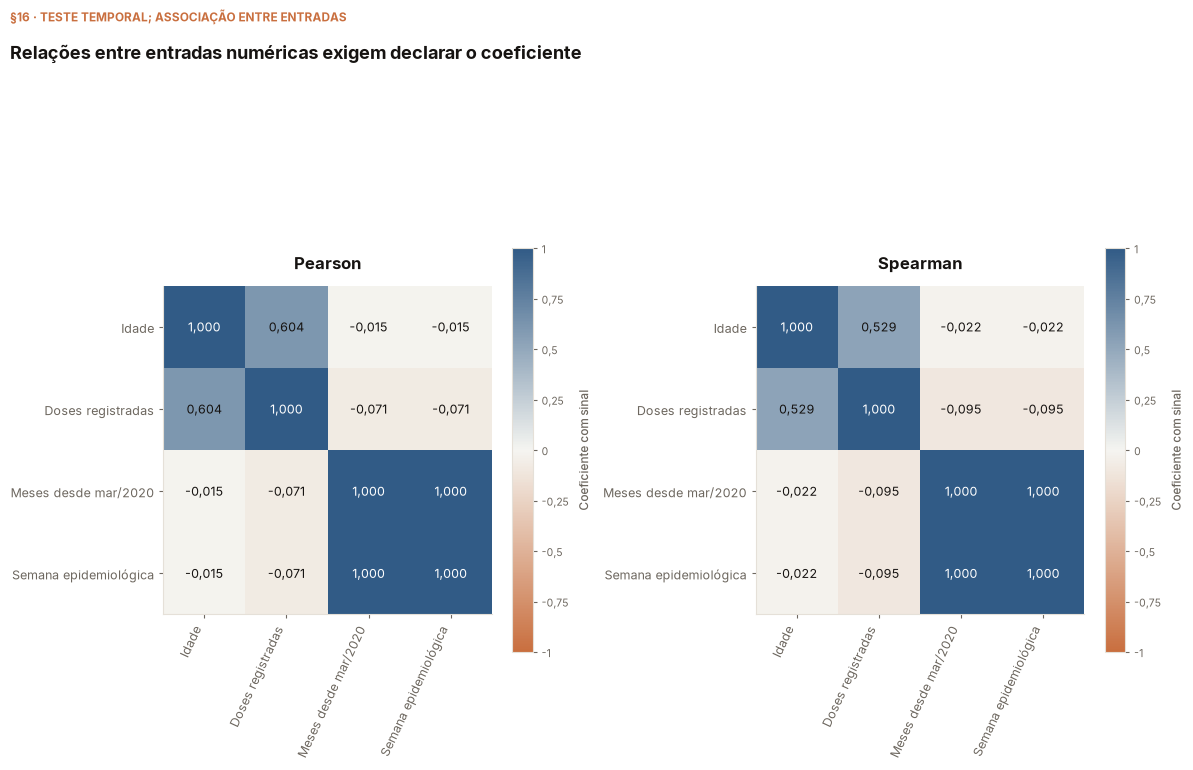

figura: figures_generated/input-associations-categorical-observed.png


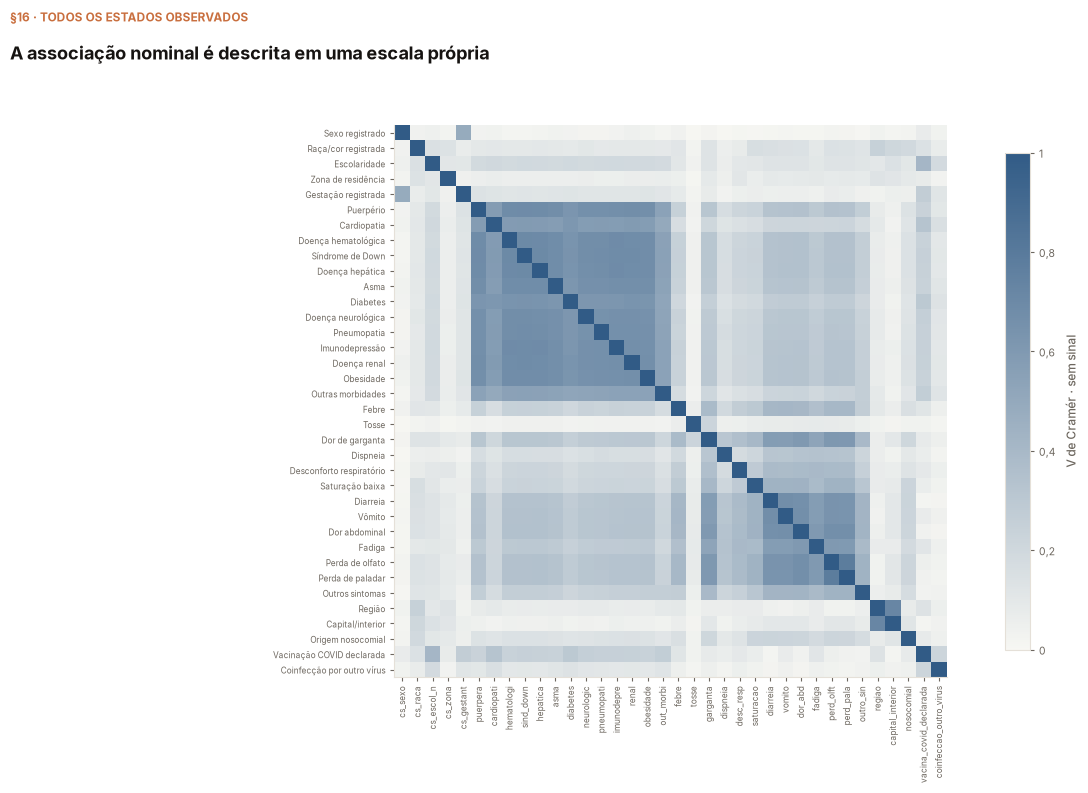

figura: figures_generated/input-associations-categorical-without_absence_codes.png


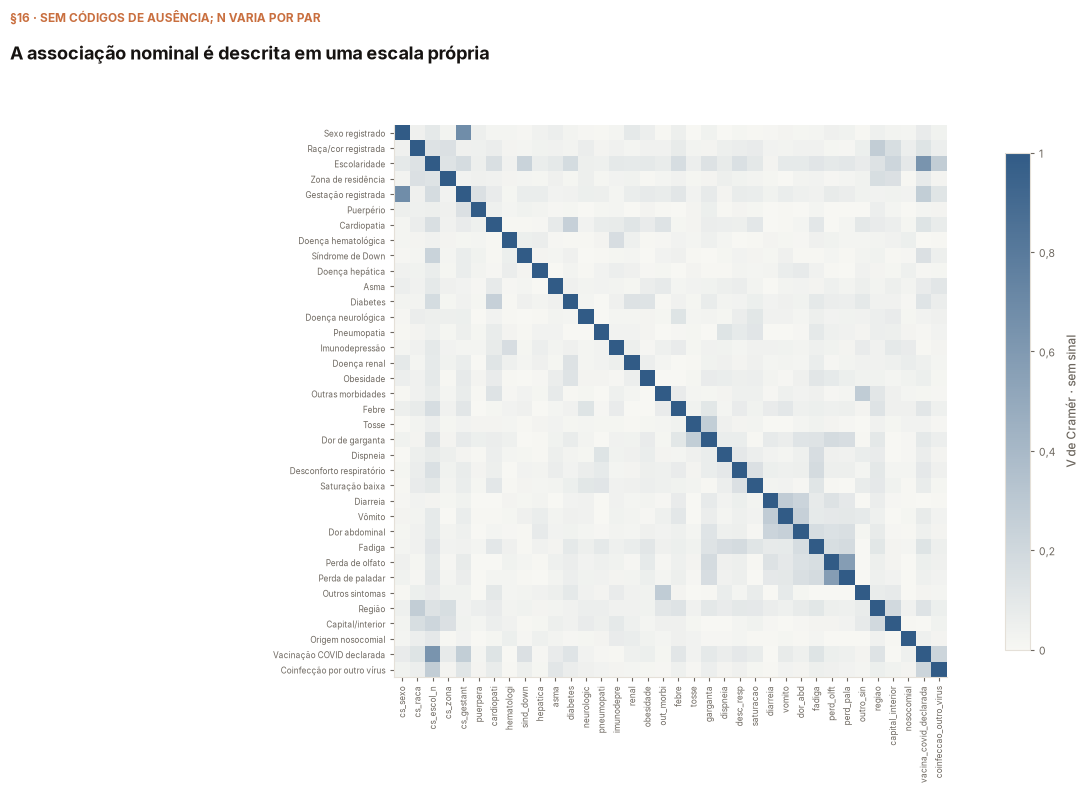

Figuras geradas fora da árvore versionada; nenhuma promoção automática.


In [16]:
from matplotlib.colors import LinearSegmentedColormap
association_diverging = LinearSegmentedColormap.from_list("sapians-association-signed", [SP.TERRACOTA, "#f5f5f1", SP.AZUL])
association_sequential = LinearSegmentedColormap.from_list("sapians-association-strength", ["#f7f7f3", SP.AZUL])
fig, axes = plt.subplots(1, 2, figsize=SP.PAINEL)
short_numeric = ["Idade", "Doses registradas", "Meses desde mar/2020", "Semana epidemiológica"]
for ax, method in zip(axes, ["pearson", "spearman"]):
    matrix = association_payload["matrices"][method]
    array = np.array([[np.nan if value is None else value for value in row] for row in matrix["values"]])
    image = ax.imshow(array, vmin=-1, vmax=1, cmap=association_diverging)
    ax.set_xticks(range(len(short_numeric)), short_numeric, rotation=65, ha="right", fontsize=9)
    ax.set_yticks(range(len(short_numeric)), short_numeric, fontsize=9)
    ax.set_title("Pearson" if method == "pearson" else "Spearman", fontsize=12)
    ax.grid(False)
    for i in range(len(short_numeric)):
        for j in range(len(short_numeric)):
            value = matrix["values"][i][j]
            ax.text(j, i, "NA" if value is None else SP.pt(value, 3), ha="center", va="center",
                fontsize=9, color="white" if value is not None and abs(value) > .65 else SP.ESCURO)
    fig.colorbar(image, ax=ax, shrink=.62, label="Coeficiente com sinal")
SP.titulo(fig, "Relações entre entradas numéricas exigem declarar o coeficiente", "§16 · teste temporal; associação entre entradas")
SP.salvar(fig, "input-associations-numeric")
display(fig)
plt.close(fig)
for mode, subtitle in [("observed", "Todos os estados observados"),
                        ("without_absence_codes", "Sem códigos de ausência; N varia por par")]:
    matrix = association_payload["matrices"]["cramers_v_" + mode]
    array = np.array([[np.nan if value is None else value for value in row] for row in matrix["values"]])
    fig, ax = plt.subplots(figsize=SP.PAINEL)
    image = ax.imshow(array, vmin=0, vmax=1, cmap=association_sequential)
    ax.set_xticks(range(len(association_categorical)), association_categorical, rotation=90, fontsize=6)
    ax.set_yticks(range(len(association_categorical)), [association_labels[f] for f in association_categorical], fontsize=6)
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=.9, label="V de Cramér · sem sinal")
    SP.titulo(fig, "A associação nominal é descrita em uma escala própria", "§16 · " + subtitle)
    SP.salvar(fig, "input-associations-categorical-" + mode)
    display(fig)
    plt.close(fig)
print("Figuras geradas fora da árvore versionada; nenhuma promoção automática.")


**O que olhar.**

- Compare Pearson com Spearman somente na mesma população e nas mesmas entradas.
  Uma relação temporal construída não é uma associação clínica descoberta.
- Nas nominais, leia o N do próprio par e abra a tabela de contagens. A retirada
  de códigos de ausência também muda quais registros participam da descrição.
- O diagnóstico de idade e doses mede feature–feature; não usa óbito e não
  demonstra redundância nem como o preditor compartilha informação entre entradas.
- As matrizes orientam a investigação de um exemplo; não estimam PFI e não
  tornam equivalentes as diferentes regras de permutação. A inspeção entre pares
  também não revela necessariamente toda dependência entre várias entradas.


## §17 — Prévia categórica local: cardiopatia e diabetes

Sorteamos receptores uniformemente do teste completo, sem selecionar por qualquer
entrada, desfecho, previsão ou perda. Uma leitura própria contém somente
cardiopatia, diabetes, split e ano. Não lê óbito, identificadores, datas ou
localidades individuais.

A primeira ordem global é a mesma do registro da PFI. Os doadores pertencem ao
teste inteiro, inclusive fora da janela visível. A versão restrita filtra essa
ordem pela categoria original de diabetes. Ambas as versões começam novamente
nos valores originais de cardiopatia, sem embaralhamento acumulado. O esquema
não altera nem treina modelo, não calcula previsões ou perdas novas, e não
estima a importância a partir dos receptores mostrados.

O JSON com entradas é exclusivamente apoio local de prototipação, escrito fora
do repositório. Os outputs abaixo contêm somente regras, hashes, invariantes e
contagens agregadas. Uma coordenada categórica pode conter muitos receptores:
seus estados não são convertidos em medidas clínicas contínuas. Desconhecido
permanece uma categoria, e não é transformado em Não.


In [17]:
import hashlib

preview_source = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
preview_record_path = REPO / "modules/00-dataset/gold/pfi_ranking.json"
preview_aggregate_path = REPO / "modules/06-pfi/lecture/pfi-interactive/data/pfi-aggregates.json"
preview_record = json.loads(preview_record_path.read_text())
preview_aggregate = json.loads(preview_aggregate_path.read_text())
preview_protocol = preview_record["protocol"]
preview_source_hash = hashlib.sha256(preview_source.read_bytes()).hexdigest()
assert preview_source_hash == preview_protocol["sample_sha256"]
preview_columns = ["split", "ano_onset", "cardiopati", "diabetes"]
preview_projection = pd.read_parquet(preview_source, columns=preview_columns)
assert "y_obito" not in preview_projection.columns
preview_test = preview_projection.loc[preview_projection["split"].eq("test")].reset_index(drop=True)
assert len(preview_test) == preview_protocol["n_evaluation"]
assert preview_test["ano_onset"].eq(preview_protocol["period"]).all()
preview_heart = preview_test["cardiopati"].to_numpy()
preview_diabetes = preview_test["diabetes"].to_numpy()
preview_rng = np.random.default_rng(preview_protocol["permutation_seed"])
preview_orders = [preview_rng.permutation(len(preview_test)) for _ in range(preview_protocol["repeats"])]
preview_orders_hash = hashlib.sha256(np.asarray(preview_orders).tobytes()).hexdigest()
assert preview_orders_hash == preview_protocol["permutation_orders_sha256"]
preview_first = preview_orders[0]

# The visual selection has its own independent random generator.
preview_selected = np.sort(np.random.default_rng(42).choice(len(preview_test), size=300, replace=False))
def preview_restricted_order(groups):
    restricted = np.arange(len(groups), dtype=preview_first.dtype)
    for level in pd.unique(groups):
        same = pd.isna(groups) if pd.isna(level) else groups == level
        receivers = np.flatnonzero(same)
        donors = preview_first[same[preview_first]]
        assert len(receivers) == len(donors)
        restricted[receivers] = donors
    np.testing.assert_array_equal(np.sort(restricted), np.arange(len(groups)))
    pd.testing.assert_series_equal(pd.Series(groups[restricted]), pd.Series(groups))
    return restricted
preview_diabetes_order = preview_restricted_order(preview_diabetes)

def preview_canonical(value):
    return json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()
def preview_category(value):
    return None if pd.isna(value) else str(value)
def preview_levels(values):
    return sorted(pd.unique(pd.Series(values).dropna()).tolist())
def preview_order_hash(order):
    return hashlib.sha256(order.astype("<i8").tobytes()).hexdigest()
preview_selection = {
    "method": "uniform sample without replacement from every temporal-test receiver; no feature, outcome, prediction or loss filter",
    "seed": 42, "n": len(preview_selected),
    "display_order": "original test position order after selection",
    "random_stream": "independent default_rng(42), separate from permutation stream",
    "selection_positions_sha256": preview_order_hash(preview_selected),
}
preview_baseline = {
    "path": "modules/06-pfi/lecture/pfi-interactive/data/pfi-aggregates.json",
    "sha256_bytes": hashlib.sha256(preview_aggregate_path.read_bytes()).hexdigest(),
    "scope": "recorded full-test reference only; no preview-score claim",
    "metric": "logloss", "original_loss": preview_aggregate["original"]["logloss"],
    "model": preview_aggregate["protocol"]["model"],
}
def preview_source_metadata(projection):
    return {"path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet",
        "sha256_bytes": preview_source_hash, "split": "test",
        "period": int(preview_protocol["period"]), "evaluation_n": len(preview_test),
        "projection_sha256": hashlib.sha256(preview_canonical(projection)).hexdigest()}
def preview_permutation(feature, fixed_input, within, rule, reset):
    return {"feature": feature, "fixed_display_input": fixed_input,
        "generator": "numpy.random.default_rng(seed).permutation(evaluation_n)",
        "seed": int(preview_protocol["permutation_seed"]), "displayed_repeat": 1,
        "donors": "all original temporal-test rows, including rows outside the display sample",
        "all_registered_orders_sha256": preview_orders_hash,
        "first_marginal_order_sha256": preview_order_hash(preview_first),
        "first_within_order_sha256": preview_order_hash(within),
        "within_rule": rule, "reset": reset,
        "no_predictions_computed": True, "no_model_fitted_or_loaded": True}

preview_categorical_rows = [{"heart_original": preview_category(preview_heart[i]),
    "diabetes": preview_category(preview_diabetes[i]),
    "heart_after_marginal": preview_category(preview_heart[preview_first[i]]),
    "heart_after_within": preview_category(preview_heart[preview_diabetes_order[i]])} for i in preview_selected]
def preview_categorical_summary(field):
    pairs = [(row[field], row["diabetes"]) for row in preview_categorical_rows]
    frequencies = pd.Series(pairs).value_counts()
    return {"unique_coordinates": len(set(pairs)),
        "overlapping_records": len(preview_categorical_rows) - len(set(pairs)),
        "maximum_records_at_same_coordinate": int(frequencies.max())}
def preview_contingency(heart_values, diabetes_values, state):
    table = pd.crosstab(pd.Series(heart_values, name="cardiopati").astype("string").fillna("[NA]"),
                        pd.Series(diabetes_values, name="diabetes").astype("string").fillna("[NA]"))
    return {"state": state, "row_levels": list(map(str, table.index)),
        "column_levels": list(map(str, table.columns)),
        "counts": table.to_numpy(dtype=int).tolist(), "n": int(table.to_numpy().sum())}
preview_categorical_contingency = {"full": [], "display": []}
for state, values in [("heart_original", preview_heart),
                       ("heart_after_marginal", preview_heart[preview_first]),
                       ("heart_after_within", preview_heart[preview_diabetes_order])]:
    preview_categorical_contingency["full"].append(preview_contingency(values, preview_diabetes, state))
    preview_categorical_contingency["display"].append(preview_contingency(values[preview_selected], preview_diabetes[preview_selected], state))
assert preview_categorical_contingency["full"][0]["counts"] == preview_categorical_contingency["full"][2]["counts"]
preview_categorical_payload = {
    "status": "local design preview only; not published; not a PFI estimate",
    "source": preview_source_metadata([{"heart": preview_category(heart), "diabetes": preview_category(diabetes)}
        for heart, diabetes in zip(preview_heart, preview_diabetes)]),
    "selection": dict(preview_selection),
    "permutation": preview_permutation("cardiopati", "diabetes", preview_diabetes_order,
        "For each observed diabetes category (including missing if present), filter the same first global permutation to donors of that category and assign them to receiver positions of that category in original order.",
        "Both changed heart-disease fields are taken independently from the original full-test heart-disease vector; subgroup shuffling never starts from marginally shuffled heart-disease values."),
    "baseline_reference": dict(preview_baseline),
    "definitions": {
        "heart": "Observed processed cardiopati category; original strings retained, including desconhecido.",
        "diabetes": "Observed processed diabetes category; stays fixed in its original receiver row.",
        "subgroups": "Observed diabetes categories; not death/survival outcome classes.",
        "unknown": "desconhecido is a recorded input category; it is not recoded as nao.",
        "coordinates": "X = heart-disease category; Y = diabetes category. Only X changes. Category positions are labels, not continuous clinical measurements.",
        "overlap": "Several records may share the same category pair. Counts describe overlap; no invented numeric values or clinical distance is implied."},
    "visual_summary": {
        "levels_in_full_test": {"heart": preview_levels(preview_heart), "diabetes": preview_levels(preview_diabetes)},
        "levels_in_display": {"heart": preview_levels([row["heart_original"] for row in preview_categorical_rows]),
            "diabetes": preview_levels([row["diabetes"] for row in preview_categorical_rows])},
        "states": {field: preview_categorical_summary(field) for field in ["heart_original", "heart_after_marginal", "heart_after_within"]},
        "contingency": preview_categorical_contingency},
    "rows": preview_categorical_rows,
}
assert all(set(row) == {"heart_original", "diabetes", "heart_after_marginal", "heart_after_within"} for row in preview_categorical_rows)

print("Prévia local: teste de", str(preview_protocol["period"]), "; receptores completos:", SP.pt_int(len(preview_test)))
print("Receptores da janela uniforme:", SP.pt_int(len(preview_selected)), "; semente de seleção:", SP.pt_int(preview_selection["seed"]))
print("Ordens registradas:", SP.pt_int(len(preview_orders)), "; ordem mostrada:", SP.pt_int(1), "; semente da permutação:", SP.pt_int(preview_protocol["permutation_seed"]))
print("Seleção:", preview_selection["method"])
print("SHA256 do parquet:", preview_source_hash)
print("SHA256 das posições sorteadas:", preview_selection["selection_positions_sha256"])
print("SHA256 de todas as ordens globais:", preview_orders_hash)
print("SHA256 da primeira ordem marginal:", preview_order_hash(preview_first))
print("SHA256 da primeira ordem restrita por diabetes:", preview_order_hash(preview_diabetes_order))
print("SHA256 da projeção cardiopatia/diabetes:", preview_categorical_payload["source"]["projection_sha256"])
print("SHA256 dos quatro campos categóricos da janela:", hashlib.sha256(preview_canonical(preview_categorical_rows)).hexdigest())
print("Projeção contém y_obito:", "y_obito" in preview_projection.columns)
print("Doadores do teste completo, incluindo fora da janela:", True)
print("Grupos originais preservados pelas ordens restritas:", True)
print("Cada versão parte dos valores originais, sem acumular o embaralhamento marginal:", True)
print("Tabela cardiopatia/diabetes preservada exatamente pela ordem restrita no teste completo:", True)
print("Essas igualdades da população completa não exigem igualdade das contagens na janela sorteada.")
print("Nenhuma chamada a fit ou predict nesta seção:", True)
print("Sobreposição nas coordenadas categóricas, sem criar medidas numéricas:")
print(SP.tabela(pd.DataFrame([{"estado": key, **value} for key, value in preview_categorical_payload["visual_summary"]["states"].items()]), casas=6))
for scope, tables in preview_categorical_contingency.items():
    for table in tables:
        print("Tabela agregada:", scope, table["state"], "; N:", SP.pt_int(table["n"]))
        table_frame = pd.DataFrame(table["counts"], index=table["row_levels"], columns=table["column_levels"])
        print(SP.tabela(table_frame.reset_index(names="cardiopatia / diabetes"), casas=0))

preview_folder = WORK / "figures_generated"
preview_folder.mkdir(exist_ok=True)
for name, payload in [("categorical-preview.json", preview_categorical_payload)]:
    output = preview_folder / name
    output.write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
    print("Arquivo de prototipação gerado fora do repositório:", output.name)
    print("SHA256 do JSON:", hashlib.sha256(output.read_bytes()).hexdigest())
print("Os outputs do caderno contêm apenas agregados; os JSONs de entradas ficam fora da árvore versionada e não são publicados por esta seção.")


Prévia local: teste de 2024 ; receptores completos: 16.142
Receptores da janela uniforme: 300 ; semente de seleção: 42
Ordens registradas: 50 ; ordem mostrada: 1 ; semente da permutação: 42
Seleção: uniform sample without replacement from every temporal-test receiver; no feature, outcome, prediction or loss filter
SHA256 do parquet: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 das posições sorteadas: d07066985775f9fe0d3a736dfa6af2d26ff3d4e739b7e6c9d051b94f23a97f51
SHA256 de todas as ordens globais: 93f4064c96d8b86e6ed1eb5a3a5d486b9894223de180e609bdaf008dcddd651d
SHA256 da primeira ordem marginal: 54fefcd8edc669918662a51ee22e976306f250a0d2d5d8b1b4b8b55207aa637c
SHA256 da primeira ordem restrita por diabetes: fce27f5a702bb70602252ad7539cebf5a9baf802a9264c9af85e3e5d316bea5a
SHA256 da projeção cardiopatia/diabetes: 7b6d782f9dbb250045d92b20ed0926e30352c87790b9f70948cf4e620a086d31
SHA256 dos quatro campos categóricos da janela: 978bac5a310d98709d3b2be3014e65cf4ad5e

## §18 — Laboratório de dependência: comparar distribuições reais antes do motion

Comparamos candidatos definidos para exploração didática, sem escolher um
vencedor pelo maior coeficiente. Olfato/paladar, gestação/sexo e campos de
vacinação oferecem relações de natureza diferente; cardiopatia/diabetes mantém
o controle já estudado, e desconforto/dispneia é um contraste respiratório.

A análise usa todo o teste temporal, sem amostragem. A mesma primeira ordem
registrada produz a permutação livre de X. A versão restrita filtra essa ordem
pelos grupos originais de Y. Cada operação recomeça nos valores originais.
Y permanece fixo. Não usamos óbito e não ajustamos nem consultamos o modelo:
o que medimos aqui são frequências e associação entre entradas, não PFI.

As tabelas têm linhas Y e colunas X. O grupo é uma entrada, nunca o desfecho.
Desconhecido fica visível. O recorte sem códigos explícitos de ausência é
somente uma sensibilidade da associação original; não geramos outra permutação
nesse recorte. Ele muda os registros descritos e não identifica um efeito
causal do preenchimento.

Exportamos somente agregados: contagens, P(X|Y), V de Cramér, fluxos entre
categorias dos doadores e transições de valores dos receptores. Um fluxo
ilustrativo é escolhido entre trocas reais de X, preferindo estados sem
códigos de ausência. Esse destaque não é uma amostra probabilística nem uma
estimativa de relevância: todas as contagens continuam disponíveis.


In [18]:
import hashlib
from scipy.stats.contingency import association
import srag_60_model as M

lab_source = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
lab_record_path = REPO / "modules/00-dataset/gold/pfi_ranking.json"
lab_record = json.loads(lab_record_path.read_text())
lab_protocol = lab_record["protocol"]
lab_source_hash = hashlib.sha256(lab_source.read_bytes()).hexdigest()
assert lab_source_hash == lab_protocol["sample_sha256"]
lab_configs = [
    {"id": "smell-taste", "label": "Olfato e paladar",
     "x": "perd_olft", "x_label": "Perda de olfato", "y": "perd_pala", "y_label": "Perda de paladar",
     "notes": ["São dois sintomas registrados. A coocorrência não prova causa, redundância nem uso pelo modelo.",
               "Desconhecido compartilhado é distinto de presença conjunta dos sintomas."]},
    {"id": "pregnancy-sex", "label": "Gestação e sexo registrados",
     "x": "cs_gestant", "x_label": "Gestação registrada", "y": "cs_sexo", "y_label": "Sexo registrado",
     "notes": ["A relação inclui regras e estados estruturais do formulário. Não é uma fronteira biológica inferida desta tabela.",
               "nao_se_aplica é preservado. idade_gestacional_ignorada informa gestação, mas não o trimestre."]},
    {"id": "vaccine-registration", "label": "Campos de vacinação",
     "x": "n_doses_antes_do_sintoma", "x_label": "Datas de doses registradas antes dos sintomas",
     "y": "vacina_covid_declarada", "y_label": "Vacinação COVID declarada",
     "notes": ["A contagem é tratada como nominal somente neste diagnóstico de associação e permutação.",
               "Gold soma campos com data registrada estritamente anterior aos sintomas, sem deduplicar datas.",
               "Zero não comprova ausência de vacinação. False não certifica ausência de vacina: a transformação já reúne valores sem declaração positiva."]},
    {"id": "cardio-diabetes", "label": "Cardiopatia e diabetes · controle anterior",
     "x": "cardiopati", "x_label": "Cardiopatia", "y": "diabetes", "y_label": "Diabetes",
     "notes": ["Retoma o diagnóstico anterior para comparação do mecanismo, sem adotar outro modelo.",
               "A associação inclui estados Desconhecido compartilhados; não é uma medida de causalidade clínica."]},
    {"id": "breathing", "label": "Desconforto respiratório e dispneia · contraste",
     "x": "desc_resp", "x_label": "Desconforto respiratório", "y": "dispneia", "y_label": "Dispneia",
     "notes": ["Sintomas relacionados podem ocorrer separadamente. A tabela não define combinações clinicamente impossíveis.",
               "Este contraste não é apresentado como dependência forte por pressuposição."]},
]
lab_features = list(dict.fromkeys(feature for config in lab_configs for feature in [config["x"], config["y"]]))
assert set(lab_features) <= set(M.FEATURES)
lab_projection = pd.read_parquet(lab_source, columns=["split", "ano_onset"] + lab_features)
assert "y_obito" not in lab_projection.columns
lab_test = lab_projection.loc[lab_projection["split"].eq("test")].reset_index(drop=True)
assert len(lab_test) == lab_protocol["n_evaluation"]
assert lab_test["ano_onset"].eq(lab_protocol["period"]).all()
lab_rng = np.random.default_rng(lab_protocol["permutation_seed"])
lab_orders = [lab_rng.permutation(len(lab_test)) for _ in range(lab_protocol["repeats"])]
lab_orders_hash = hashlib.sha256(np.asarray(lab_orders).tobytes()).hexdigest()
assert lab_orders_hash == lab_protocol["permutation_orders_sha256"]
lab_first = lab_orders[0]
lab_identity = np.arange(len(lab_test), dtype=lab_first.dtype)
lab_level_labels = {
    "desconhecido": "Desconhecido", "ignorado": "Ignorado", "[NA]": "Ausente",
    "nao": "Não", "sim": "Sim", "feminino": "Feminino", "masculino": "Masculino",
    "1_trimestre": "1º trimestre", "2_trimestre": "2º trimestre", "3_trimestre": "3º trimestre",
    "idade_gestacional_ignorada": "Gestação: trimestre ignorado", "nao_se_aplica": "Não se aplica",
    "False": "Sem declaração de Sim", "True": "Sim declarado",
}
lab_orders_preferred = {
    "cs_gestant": ["1_trimestre", "2_trimestre", "3_trimestre", "idade_gestacional_ignorada", "nao", "nao_se_aplica", "desconhecido", "[NA]"],
    "cs_sexo": ["feminino", "masculino", "ignorado", "desconhecido", "[NA]"],
}
def lab_strings(series):
    return series.astype("string").fillna("[NA]").to_numpy(dtype=str)
def lab_levels(values, feature):
    observed = set(values)
    preferred = lab_orders_preferred.get(feature, ["nao", "sim", "desconhecido", "ignorado", "False", "True", "[NA]"])
    return [value for value in preferred if value in observed] + sorted(observed - set(preferred))
def lab_absence(feature):
    if feature == "cs_sexo":
        return ["desconhecido", "ignorado", "[NA]"]
    if feature in {"n_doses_antes_do_sintoma", "vacina_covid_declarada"}:
        return ["[NA]"]
    return ["desconhecido", "[NA]"]
def lab_variable(feature, label, values):
    levels = lab_levels(values, feature)
    return {"key": feature, "label": label, "levels": levels,
        "level_labels": {level: lab_level_labels.get(level, level) for level in levels},
        "absence_codes": lab_absence(feature),
        "structural_levels": ["nao_se_aplica"] if feature == "cs_gestant" else [],
        "partial_information_levels": ["idade_gestacional_ignorada"] if feature == "cs_gestant" else [],
        "type": "count_as_nominal" if feature == "n_doses_antes_do_sintoma" else "boolean" if feature == "vacina_covid_declarada" else "categorical",
        "notes": []}
def lab_table(x, y, x_levels, y_levels):
    return pd.crosstab(pd.Series(y), pd.Series(x)).reindex(index=y_levels, columns=x_levels, fill_value=0)
def lab_association(table):
    count = int(table.to_numpy().sum())
    active = table.loc[table.sum(axis=1).gt(0), table.sum(axis=0).gt(0)]
    reason = "sem observações válidas" if count == 0 else "entrada constante no recorte" if min(active.shape) < 2 else None
    value = None if reason else float(association(active.to_numpy(), method="cramer", correction=False))
    return count, value, reason

def lab_group_summaries(table):
    result = []
    for group, row in table.iterrows():
        group_n = int(row.sum())
        result.append({"y": str(group), "n": group_n,
            "levels": [{"x": str(level), "n": int(count), "p_x_given_y": float(count / group_n) if group_n else None}
                for level, count in row.items()]})
    return result

def lab_aggregate(frame, keys):
    counts = frame.groupby(keys, observed=True, sort=True).size().reset_index(name="n")
    return [{**{key: str(row[key]) for key in keys}, "n": int(row["n"])} for _, row in counts.iterrows()]
def lab_representative(rows, mode, absent_x, absent_y):
    candidates = [row for row in rows if row["donorX"] != row["receiverX"]
        and ((row["donorY"] != row["receiverY"]) if mode == "marginal" else (row["donorY"] == row["receiverY"]))]
    preferred = [row for row in candidates if row["donorX"] not in absent_x and row["receiverX"] not in absent_x
        and row["donorY"] not in absent_y and row["receiverY"] not in absent_y]
    pool = preferred or candidates
    selected = sorted(pool, key=lambda row: (-row["n"], row["donorY"], row["receiverY"], row["donorX"], row["receiverX"]))[0] if pool else None
    return {"selection_rule": "Destaque didático agregado: mudança real de X; grupo diferente na livre ou igual na restrita; preferir estados sem códigos de ausência; maior contagem e desempate lexical. Não é amostra probabilística nem medida de importância.",
        "preferred_without_absence_codes": bool(preferred), "flow": selected}

lab_payload = {
    "schema_version": "srag-dependence-laboratory-v1",
    "metadata": {"n": len(lab_test), "year": int(lab_protocol["period"]), "split": "test",
        "source_path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet",
        "source_sha256": lab_source_hash, "source_notebook": "modules/00-dataset/notebooks/srag_pfi_ranking.ipynb",
        "source_section": "§18", "permutation_seed": int(lab_protocol["permutation_seed"]),
        "displayed_repeat": 1, "registered_repeats": int(lab_protocol["repeats"]),
        "all_orders_sha256": lab_orders_hash,
        "first_order_sha256": hashlib.sha256(lab_first.astype("<i8").tobytes()).hexdigest(),
        "sampling": "none; complete temporal test", "analysis_excludes_outcome": True,
        "model_used": False, "diagnostic": "input-pair frequencies and association; not PFI or prediction loss",
        "counts_orientation": "rows are fixed Y groups; columns are mobile X categories",
        "scope": "local exploratory comparison; no automatic slide replacement or publication"},
    "rules": {
        "same_order": "Todos os pares usam a mesma primeira ordem global registrada, com doadores do teste completo.",
        "reset": "Livre e restrita partem separadamente do X original; Y e a ordem dos receptores permanecem fixos.",
        "within": "Filtrar a primeira ordem global pelos estados originais de Y e atribuir os doadores nas posições originais de cada grupo.",
        "association": "V de Cramér não corrigido, correction=False; associação nominal sem sinal, não correlação de Pearson nem PFI.",
        "unknown": "Todos os estados observados ficam visíveis por padrão. Ausência não é recodificada como Não.",
        "sensitivity": "Sem códigos explícitos de ausência é somente associação da tabela original em outro recorte; nenhuma permutação nova é realizada nele.",
        "flow": "donorY é o estado original de Y no doador; receiverY é o estado fixo de Y no receptor; donorX é o valor recebido; receiverX é o X original do receptor. Não são pessoas mudando de grupo.",
        "zero_flows": "Listas de fluxos registram somente contagens positivas. Combinações ausentes nessas listas têm contagem zero.",
        "interpretation": "Dependência nos registros não prova causa, redundância, impossibilidade clínica ou uso pelo preditor. Coausência e regras de formulário devem ser distinguidas de relações clínicas.",
    },
    "pairs": [],
}
print("Laboratório local; ano do teste:", str(lab_protocol["period"]))
print("Registros completos:", SP.pt_int(len(lab_test)), "; candidatos:", SP.pt_int(len(lab_configs)))
print("Semente:", SP.pt_int(lab_protocol["permutation_seed"]), "; ordem mostrada:", SP.pt_int(1), "; ordens registradas:", SP.pt_int(len(lab_orders)))
print("Fonte:", lab_payload["metadata"]["source_path"])
print("SHA256 do parquet:", lab_source_hash)
print("SHA256 das ordens:", lab_orders_hash)
print("SHA256 da primeira ordem:", lab_payload["metadata"]["first_order_sha256"])
print("Projeção contém y_obito:", "y_obito" in lab_projection.columns)
for key, rule in lab_payload["rules"].items():
    print(key + ":", rule)

for config in lab_configs:
    x_original = lab_strings(lab_test[config["x"]])
    y_original = lab_strings(lab_test[config["y"]])
    x_variable = lab_variable(config["x"], config["x_label"], x_original)
    y_variable = lab_variable(config["y"], config["y_label"], y_original)
    x_levels, y_levels = x_variable["levels"], y_variable["levels"]
    restricted = np.arange(len(lab_test), dtype=lab_first.dtype)
    for level in y_levels:
        receivers = np.flatnonzero(y_original == level)
        donors = lab_first[y_original[lab_first] == level]
        assert len(receivers) == len(donors)
        restricted[receivers] = donors
    np.testing.assert_array_equal(np.sort(restricted), np.arange(len(lab_test)))
    np.testing.assert_array_equal(y_original[restricted], y_original)
    pair = {"id": config["id"], "label": config["label"], "x": x_variable, "y": y_variable,
        "n": len(lab_test), "states": {}, "flows": {}, "flows_detailed": {}, "transitions": {},
        "representative_flows": {}, "notes": config["notes"],
        "source_notes": ["tools/srag_30_silver.py: harmonização e domínios de origem",
                         "tools/srag_40_gold.py: transformação das entradas no Gold"],
        "within_order_sha256": hashlib.sha256(restricted.astype("<i8").tobytes()).hexdigest()}
    original_table = lab_table(x_original, y_original, x_levels, y_levels)
    for state, order in [("original", lab_identity), ("marginal", lab_first), ("within", restricted)]:
        changed_x = x_original[order]
        table = lab_table(changed_x, y_original, x_levels, y_levels)
        count, value, reason = lab_association(table)
        assert count == len(lab_test)
        np.testing.assert_array_equal(table.sum(axis=0), original_table.sum(axis=0))
        np.testing.assert_array_equal(table.sum(axis=1), original_table.sum(axis=1))
        pair["states"][state] = {"counts": table.to_numpy(dtype=int).tolist(), "v": value,
            "n": count, "reason": reason, "changed_x_n": int(np.count_nonzero(changed_x != x_original)),
            "group_summaries": lab_group_summaries(table)}
        if state != "original":
            donor_frame = pd.DataFrame({"donorY": y_original[order], "receiverY": y_original,
                "donorX": changed_x, "receiverX": x_original})
            pair["flows"][state] = lab_aggregate(donor_frame, ["donorY", "receiverY", "donorX"])
            pair["flows_detailed"][state] = lab_aggregate(donor_frame, ["donorY", "receiverY", "donorX", "receiverX"])
            receiver_frame = pd.DataFrame({"Y": y_original, "X_original": x_original, "X_destino": changed_x})
            pair["transitions"][state] = lab_aggregate(receiver_frame, ["Y", "X_original", "X_destino"])
            for collection in [pair["flows"][state], pair["flows_detailed"][state], pair["transitions"][state]]:
                assert sum(row["n"] for row in collection) == len(lab_test)
            pair["representative_flows"][state] = lab_representative(pair["flows_detailed"][state], state,
                set(x_variable["absence_codes"]), set(y_variable["absence_codes"]))
    assert pair["states"]["original"]["counts"] == pair["states"]["within"]["counts"]
    known_mask = ~np.isin(x_original, x_variable["absence_codes"]) & ~np.isin(y_original, y_variable["absence_codes"])
    known_x_levels = [level for level in x_levels if np.any(x_original[known_mask] == level)]
    known_y_levels = [level for level in y_levels if np.any(y_original[known_mask] == level)]
    known_table = lab_table(x_original[known_mask], y_original[known_mask], known_x_levels, known_y_levels)
    known_n, known_v, known_reason = lab_association(known_table)
    pair["known_sensitivity"] = {"n": known_n, "v": known_v, "reason": known_reason,
        "x_levels": known_x_levels, "y_levels": known_y_levels,
        "counts": known_table.to_numpy(dtype=int).tolist(),
        "excluded_codes": {"x": x_variable["absence_codes"], "y": y_variable["absence_codes"]},
        "scope": "original association only; no new permutation",
        "label": "Sensibilidade: tabela original sem códigos explícitos de ausência"}
    within_cross_n = sum(row["n"] for row in pair["flows"]["within"] if row["donorY"] != row["receiverY"])
    assert within_cross_n == 0
    pair["invariance_checks"] = {"n_preserved": True, "x_marginal_preserved": True,
        "y_marginal_preserved": True, "within_table_identical": True,
        "within_donor_cross_group_n": within_cross_n,
        "marginal_donor_cross_group_n": sum(row["n"] for row in pair["flows"]["marginal"] if row["donorY"] != row["receiverY"]),
        "reset_from_original": True, "sampling_used": False}
    print("\nPAR:", config["label"], "; X:", config["x"], "; Y:", config["y"])
    print("Níveis X:", x_levels, "; níveis Y:", y_levels)
    print("Códigos de ausência X:", x_variable["absence_codes"], "; Y:", y_variable["absence_codes"])
    print("Estados estruturais preservados:", x_variable["structural_levels"], y_variable["structural_levels"])
    print("Informação parcial preservada:", x_variable["partial_information_levels"], y_variable["partial_information_levels"])
    print("SHA256 da ordem restrita:", pair["within_order_sha256"])
    for note in pair["notes"]:
        print(note)
    state_print = [{"estado": state, "N": values["n"], "V de Cramér": np.nan if values["v"] is None else values["v"],
        "X alterado": values["changed_x_n"], "razão de NA": values["reason"] or "definido"}
        for state, values in pair["states"].items()]
    print(SP.tabela(pd.DataFrame(state_print), casas=6))
    for state, values in pair["states"].items():
        print("Contagens agregadas; estado:", state, "; linhas Y, colunas X")
        print(SP.tabela(pd.DataFrame(values["counts"], index=y_levels, columns=x_levels).reset_index(names="Y / X"), casas=0))
        conditional = [{"Y": group["y"], "N do grupo": group["n"], "X": cell["x"], "N da célula": cell["n"], "P(X|Y)": cell["p_x_given_y"],
            "Percentual de fichas": None if cell["p_x_given_y"] is None else 100 * cell["p_x_given_y"]}
            for group in values["group_summaries"] for cell in group["levels"]]
        print(SP.tabela(pd.DataFrame(conditional), casas=6))
    print("Sensibilidade da associação ORIGINAL, sem outra permutação:")
    print("N:", SP.pt_int(known_n), "; V:", "NA" if known_v is None else SP.pt(known_v, 6), "; motivo:", known_reason or "definido")
    print(SP.tabela(known_table.reset_index(names="Y / X"), casas=0))
    for state in ["marginal", "within"]:
        print("Fluxos de doadores agregados:", state)
        print(SP.tabela(pd.DataFrame(pair["flows"][state]), casas=0))
        print("Fluxos com X original do receptor, agregados:", state)
        print(SP.tabela(pd.DataFrame(pair["flows_detailed"][state]), casas=0))
        print("Transições dos valores por grupo do receptor:", state)
        print(SP.tabela(pd.DataFrame(pair["transitions"][state]), casas=0))
        representative = pair["representative_flows"][state]
        print(representative["selection_rule"])
        print("Preferência sem códigos de ausência disponível:", representative["preferred_without_absence_codes"])
        if representative["flow"] is not None:
            print(SP.tabela(pd.DataFrame([representative["flow"]]), casas=0))
        else:
            print("Não existe fluxo com os critérios de mudança e grupo; nenhum exemplo foi inventado.")
    print("Invariantes:")
    print(SP.tabela(pd.DataFrame([pair["invariance_checks"]]), casas=0))
    lab_payload["pairs"].append(pair)

lab_output = WORK / "figures_generated/dependence-laboratory.json"
lab_output.parent.mkdir(exist_ok=True)
lab_output.write_text(json.dumps(lab_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo apenas agregado gerado fora do repositório:", lab_output.name)
print("SHA256 do JSON:", hashlib.sha256(lab_output.read_bytes()).hexdigest())
print("Nenhuma linha individual, identificador, data individual, desfecho ou probabilidade de modelo foi exportada.")
print("Nenhuma chamada a fit ou predict nesta seção:", True)


Laboratório local; ano do teste: 2024
Registros completos: 16.142 ; candidatos: 5
Semente: 42 ; ordem mostrada: 1 ; ordens registradas: 50
Fonte: modules/00-dataset/gold/gold_covid_obito_sample.parquet
SHA256 do parquet: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 das ordens: 93f4064c96d8b86e6ed1eb5a3a5d486b9894223de180e609bdaf008dcddd651d
SHA256 da primeira ordem: 54fefcd8edc669918662a51ee22e976306f250a0d2d5d8b1b4b8b55207aa637c
Projeção contém y_obito: False
same_order: Todos os pares usam a mesma primeira ordem global registrada, com doadores do teste completo.
reset: Livre e restrita partem separadamente do X original; Y e a ordem dos receptores permanecem fixos.
within: Filtrar a primeira ordem global pelos estados originais de Y e atribuir os doadores nas posições originais de cada grupo.
association: V de Cramér não corrigido, correction=False; associação nominal sem sinal, não correlação de Pearson nem PFI.
unknown: Todos os estados observados ficam v


PAR: Campos de vacinação ; X: n_doses_antes_do_sintoma ; Y: vacina_covid_declarada
Níveis X: [np.str_('0'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6')] ; níveis Y: ['False', 'True']
Códigos de ausência X: ['[NA]'] ; Y: ['[NA]']
Estados estruturais preservados: [] []
Informação parcial preservada: [] []
SHA256 da ordem restrita: fbabfc00e6021ea4603ddb7ab477357c7e52d1d9c9c16566e7cce802b3b4834a
A contagem é tratada como nominal somente neste diagnóstico de associação e permutação.
Gold soma campos com data registrada estritamente anterior aos sintomas, sem deduplicar datas.
Zero não comprova ausência de vacinação. False não certifica ausência de vacina: a transformação já reúne valores sem declaração positiva.
  estado      N V de Cramér X alterado razão de NA
original 16.142    0,962005          0    definido
marginal 16.142    0,030870     12.948    definido
  within 16.142    0,962005      9.218    definido
Contagens agregadas; estado: original 


PAR: Cardiopatia e diabetes · controle anterior ; X: cardiopati ; Y: diabetes
Níveis X: ['nao', 'sim', 'desconhecido'] ; níveis Y: ['nao', 'sim', 'desconhecido']
Códigos de ausência X: ['desconhecido', '[NA]'] ; Y: ['desconhecido', '[NA]']
Estados estruturais preservados: [] []
Informação parcial preservada: [] []
SHA256 da ordem restrita: fce27f5a702bb70602252ad7539cebf5a9baf802a9264c9af85e3e5d316bea5a
Retoma o diagnóstico anterior para comparação do mecanismo, sem adotar outro modelo.
A associação inclui estados Desconhecido compartilhados; não é uma medida de causalidade clínica.
  estado      N V de Cramér X alterado razão de NA
original 16.142    0,610936          0    definido
marginal 16.142    0,012085     10.268    definido
  within 16.142    0,610936      6.039    definido
Contagens agregadas; estado: original ; linhas Y, colunas X
       Y / X   nao   sim desconhecido
         nao 2.674 2.248            8
         sim   818 2.022          387
desconhecido    10 1.116       


PAR: Desconforto respiratório e dispneia · contraste ; X: desc_resp ; Y: dispneia
Níveis X: ['nao', 'sim', 'desconhecido'] ; níveis Y: ['nao', 'sim', 'desconhecido']
Códigos de ausência X: ['desconhecido', '[NA]'] ; Y: ['desconhecido', '[NA]']
Estados estruturais preservados: [] []
Informação parcial preservada: [] []
SHA256 da ordem restrita: 3814b067f130408771626602286e92e6cd39cc4616f25393e459354a570aabfe
Sintomas relacionados podem ocorrer separadamente. A tabela não define combinações clinicamente impossíveis.
Este contraste não é apresentado como dependência forte por pressuposição.
  estado      N V de Cramér X alterado razão de NA
original 16.142    0,179165          0    definido
marginal 16.142    0,012541      7.353    definido
  within 16.142    0,179165      7.198    definido
Contagens agregadas; estado: original ; linhas Y, colunas X
       Y / X   nao   sim desconhecido
         nao   844 1.861           11
         sim 2.386 8.687        1.203
desconhecido     7   821  

## §19 — Pares clínicos candidatos: quando Pearson tem significado

Este levantamento exploratório amplia as opções de exemplo, sem declarar um
vencedor pelo maior coeficiente e sem pretender enumerar todas as combinações
possíveis do formulário. A lista abaixo fixa as comparações desta execução:
sintomas respiratórios e gerais, sintomas gastrointestinais, olfato/paladar,
comorbidades e idade, além de dois campos de vacinação.

A leitura própria projeta somente entradas do modelo, split e ano, no mesmo
teste temporal completo. Não lê óbito, não usa previsões e não chama o modelo.
Sim e Não são codificados como um e zero; Desconhecido e NA são excluídos
separadamente por par. Pearson entre dois binários é o coeficiente phi com
sinal. Conferimos seu módulo contra V de Cramér sem correção na mesma tabela
binária. Entre uma entrada numérica e uma binária, Pearson é a correlação
ponto-bisserial. Não atribuímos números ordinais a categorias nominais.

Cada resultado informa a população do recorte, o N válido, as exclusões e a
razão quando não definido. Idade/doses é descrito no teste completo e entre
adultos; os dois recortes não são experimentos independentes. Saturação é o
indicador registrado de saturação baixa, não uma medida contínua de SpO₂.
Doses conta campos com data anterior aos sintomas, sem deduplicar datas; zero
não comprova ausência de vacinação. False no indicador de vacinação já pode
conter ausência preenchida no Gold: esse histórico não é recuperado aqui.


In [19]:
import hashlib
from scipy.stats.contingency import association
import srag_60_model as M

clinical_source = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
clinical_projection = pd.read_parquet(
    clinical_source, columns=list(M.FEATURES) + ["split", "ano_onset"]
)
assert "y_obito" not in clinical_projection.columns
clinical_test = clinical_projection.loc[clinical_projection["split"].eq("test")].reset_index(drop=True)
assert clinical_test["ano_onset"].eq(2024).all()
clinical_source_hash = hashlib.sha256(clinical_source.read_bytes()).hexdigest()
clinical_protocol = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())["protocol"]
assert clinical_source_hash == clinical_protocol["sample_sha256"]
assert len(clinical_test) == clinical_protocol["n_evaluation"]

# Exploratory candidate list declared before computing this section's results.
# Field meaning is the inclusion criterion, not the measured coefficient.
clinical_candidates = [
    ("dispneia", "desc_resp", "respiratory", "Dois sintomas respiratórios registrados; não são sinônimos nem demonstram causalidade."),
    ("dispneia", "saturacao", "respiratory", "Dispneia e indicador de saturação baixa; saturacao não contém SpO₂ numérica."),
    ("desc_resp", "saturacao", "respiratory", "Desconforto respiratório e saturação baixa são campos distintos do formulário."),
    ("tosse", "febre", "symptoms", "Dois sintomas gerais registrados; coocorrência não demonstra que um cause o outro."),
    ("tosse", "dispneia", "respiratory", "Tosse e dispneia podem descrever manifestações distintas; o coeficiente descreve o registro."),
    ("perd_olft", "perd_pala", "sensory", "Perda de olfato e de paladar são sintomas distintos; o preenchimento também deve ser inspecionado."),
    ("diarreia", "vomito", "gastrointestinal", "Dois sintomas gastrointestinais registrados, sem pressupor mecanismo comum."),
    ("dor_abd", "diarreia", "gastrointestinal", "Dor abdominal e diarreia são campos clínicos distintos; não inferimos diagnóstico."),
    ("vomito", "dor_abd", "gastrointestinal", "Vômito e dor abdominal completam a inspeção dos campos gastrointestinais."),
    ("fadiga", "febre", "symptoms", "Fadiga e febre oferecem outro contraste de sintomas gerais."),
    ("cardiopati", "diabetes", "comorbidities", "Comorbidades previamente usadas no diagnóstico; associação não prova redundância."),
    ("cardiopati", "renal", "comorbidities", "Cardiopatia e doença renal são condições registradas separadamente."),
    ("diabetes", "renal", "comorbidities", "Diabetes e doença renal: descrição entre entradas, sem desfecho hospitalar."),
    ("obesidade", "diabetes", "comorbidities", "Obesidade e diabetes: coocorrência no registro não isola idade ou outros fatores."),
    ("obesidade", "cardiopati", "comorbidities", "Obesidade e cardiopatia: diagnóstico descritivo sem ajuste por confundidores."),
    ("asma", "pneumopati", "comorbidities", "Asma e pneumopatia são campos distintos; o formulário não torna suas definições mutuamente exclusivas."),
    ("idade_anos", "cardiopati", "age", "Idade e cardiopatia registrada; Pearson não mede qualquer relação não linear."),
    ("idade_anos", "diabetes", "age", "Idade e diabetes registrada; o recorte exclui respostas sem Sim/Não."),
    ("idade_anos", "renal", "age", "Idade e doença renal registrada; correlação não representa efeito causal."),
    ("idade_anos", "saturacao", "age", "Idade e indicador de saturação baixa, não uma medida contínua de oxigenação."),
    ("idade_anos", "obesidade", "age", "Idade e obesidade registrada; formas não lineares podem não aparecer em Pearson."),
    ("idade_anos", "n_doses_antes_do_sintoma", "registration", "Idade e contagem de campos com data de dose anterior aos sintomas; inspecionar também o recorte adulto."),
    ("n_doses_antes_do_sintoma", "vacina_covid_declarada", "registration", "Dois campos do histórico de vacinação; contagem de datas e declaração não são medidas independentes de cobertura."),
]
assert len({(left, right) for left, right, _, _ in clinical_candidates}) == len(clinical_candidates)
assert all(left in M.FEATURES and right in M.FEATURES for left, right, _, _ in clinical_candidates)
clinical_keys = list(dict.fromkeys(feature for pair in clinical_candidates for feature in pair[:2]))
clinical_binary = [key for key in clinical_keys if key not in M.NUMERICAS]
assert all(key in M.COMORBIDADES + M.SINTOMAS + M.BOOLEANAS for key in clinical_binary)
clinical_labels = {key: association_labels[key] for key in clinical_keys}
clinical_rules = {
    "candidate_scope": "Levantamento exploratório de candidatos clínicos e de registro; não enumera todas as combinações possíveis e não escolhe o maior coeficiente como exemplo automaticamente.",
    "cohort": "Teste temporal completo registrado; full_test inclui todas as idades; adults_18plus exige idade_anos finita e maior ou igual a 18.",
    "binary_coding": "Campos de sintomas/comorbidades: sim=1, nao=0. Todos os demais estados, incluindo desconhecido e NA, são excluídos por par. Não há codificação ordinal de categorias nominais.",
    "boolean_coding": "Booleano de vacinação: True=1, False=0. False segue o Gold e pode incluir ausência previamente preenchida; a distinção original não é recuperável nesta projeção.",
    "numeric_coding": "Idade e contagem de campos de doses mantêm seus valores numéricos; somente observações finitas são válidas.",
    "pairwise_exclusion": "N excluído do par é N do recorte menos N válido nas duas entradas. N fora do recorte é informado separadamente.",
    "pearson": "Correlação linear com sinal, calculada com valores float64 e sem p-valor ou intervalo de confiança.",
    "binary_binary": "Pearson em dois binários coincide com phi. Conferir abs(r) contra V de Cramér sem correção na mesma tabela 2×2, sem correção de continuidade.",
    "numeric_binary": "Pearson com uma entrada numérica e uma binária coincide com a correlação ponto-bisserial; o sinal segue Sim/True=1.",
    "numeric_numeric": "Pearson entre idade e contagem de campos de doses descreve associação linear; a contagem não é uma codificação de categorias nominais.",
    "undefined": "Menos de duas observações válidas ou entrada constante gera r indisponível, nunca zero imputado.",
    "saturation": "saturacao é a resposta categórica de saturação baixa; não contém uma medida contínua de SpO₂.",
    "doses": "Soma de campos com data registrada estritamente anterior aos sintomas, sem deduplicar datas. Zero não comprova ausência de vacinação.",
    "interpretation": "Associação entre entradas não prova causa, independência, redundância ou uso pelo preditor; seleção de registros e preenchimento podem alterar os coeficientes.",
    "outcome": "A projeção desta seção não lê y_obito; nenhuma chamada a fit ou predict é feita nesta seção.",
}
clinical_payload = {
    "schema_version": "srag-clinical-pair-pearson-v1",
    "metadata": {
        "source_path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet",
        "source_sha256": clinical_source_hash,
        "source_notebook": "modules/00-dataset/notebooks/srag_pfi_ranking.ipynb",
        "source_section": "§19", "split": "test", "year": 2024,
        "n_full_test": len(clinical_test), "candidate_n": len(clinical_candidates),
        "analysis_excludes_outcome": True, "model_used": False,
        "sampling": "none; complete registered temporal test",
    },
    "rules": clinical_rules,
    "variables": [{"key": key, "label": clinical_labels[key],
        "type": "numeric" if key in M.NUMERICAS else "boolean" if key in M.BOOLEANAS else "binary_recorded",
        "coding": "numeric unchanged" if key in M.NUMERICAS else "True=1, False=0; Gold may have filled NA as False" if key in M.BOOLEANAS else "sim=1, nao=0; other states excluded"}
        for key in clinical_keys],
    "candidates": [{"left": left, "right": right, "family": family, "rationale": rationale}
        for left, right, family, rationale in clinical_candidates],
    "pairs": [],
}
print("Fonte:", clinical_payload["metadata"]["source_path"])
print("SHA256 do parquet:", clinical_source_hash)
print("Seção:", clinical_payload["metadata"]["source_section"], "; ano:", str(clinical_payload["metadata"]["year"]))
print("N do teste completo:", SP.pt_int(len(clinical_test)))
print("Candidatos distintos:", SP.pt_int(len(clinical_candidates)))
print("Projeção contém y_obito:", "y_obito" in clinical_projection.columns)
print(SP.tabela(pd.DataFrame(clinical_payload["variables"]), casas=6))
print("Lista de candidatos desta execução, definida antes do cálculo abaixo:")
print(SP.tabela(pd.DataFrame(clinical_payload["candidates"]), casas=6))
for key, rule in clinical_rules.items():
    print(key + ":", rule)


def clinical_encode(frame, key):
    if key in M.NUMERICAS:
        return pd.to_numeric(frame[key], errors="coerce").astype("float64")
    if key in M.BOOLEANAS:
        return frame[key].astype(object).map({False: 0.0, True: 1.0}).astype("float64")
    return frame[key].astype(object).map({"nao": 0.0, "sim": 1.0}).astype("float64")


clinical_result_print = []
clinical_raw_print = []
clinical_max_v_difference = 0.0
for left, right, family, rationale in clinical_candidates:
    scopes = ["full_test", "adults_18plus"] if (left, right) == ("idade_anos", "n_doses_antes_do_sintoma") else ["full_test"]
    for scope in scopes:
        scope_mask = np.ones(len(clinical_test), dtype=bool)
        if scope == "adults_18plus":
            age = pd.to_numeric(clinical_test["idade_anos"], errors="coerce")
            scope_mask = (np.isfinite(age) & age.ge(18)).to_numpy()
        frame = clinical_test.loc[scope_mask, [left, right]]
        left_values, right_values = clinical_encode(frame, left), clinical_encode(frame, right)
        left_valid, right_valid = np.isfinite(left_values), np.isfinite(right_values)
        valid = left_valid & right_valid
        a, b = left_values.loc[valid], right_values.loc[valid]
        n = len(a)
        reason = "menos de duas observações válidas" if n < 2 else "entrada constante" if min(a.nunique(), b.nunique()) < 2 else None
        r = None if reason else float(a.corr(b, method="pearson"))
        assert r is None or np.isfinite(r)
        left_is_numeric, right_is_numeric = left in M.NUMERICAS, right in M.NUMERICAS
        method = "numeric_numeric" if left_is_numeric and right_is_numeric else "point_biserial" if left_is_numeric or right_is_numeric else "phi"
        result = {
            "id": left + "--" + right + "--" + scope, "left": left, "right": right,
            "left_label": clinical_labels[left], "right_label": clinical_labels[right],
            "family": family, "scope": scope, "n_cohort": len(frame),
            "n_outside_cohort": len(clinical_test) - len(frame), "n": n,
            "n_excluded": len(frame) - n, "left_invalid_n": int((~left_valid).sum()),
            "right_invalid_n": int((~right_valid).sum()),
            "both_invalid_n": int((~left_valid & ~right_valid).sum()),
            "method": method, "pearson_r": r, "reason": reason,
            "cramers_v": None, "abs_r_minus_v": None, "contingency": None,
            "numeric_group_summaries": [], "notes": [rationale],
        }
        for key in [left, right]:
            raw = frame[key].astype(object).where(frame[key].notna(), "[NA]")
            if key not in M.NUMERICAS:
                for level, count in raw.value_counts(dropna=False, sort=False).items():
                    clinical_raw_print.append({"par": result["id"], "campo": key, "estado bruto": str(level), "N": int(count)})
        if method == "phi":
            table = pd.crosstab(a, b).reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0)
            assert int(table.to_numpy().sum()) == n
            v = None if reason else float(association(table.to_numpy(), method="cramer", correction=False))
            difference = None if reason else abs(abs(r) - v)
            if difference is not None:
                assert difference < 1e-12
                clinical_max_v_difference = max(clinical_max_v_difference, difference)
            result.update(cramers_v=v, abs_r_minus_v=difference,
                contingency={"row_feature": left, "column_feature": right,
                    "levels": [0, 1], "level_labels": ["Não", "Sim"],
                    "counts": table.to_numpy(dtype=int).tolist()})
        elif method == "point_biserial":
            number, indicator = (a, b) if left_is_numeric else (b, a)
            numeric_key, binary_key = (left, right) if left_is_numeric else (right, left)
            result["numeric_feature"], result["binary_feature"] = numeric_key, binary_key
            for value in [0, 1]:
                selected = number.loc[indicator.eq(value)]
                result["numeric_group_summaries"].append({
                    "binary_value": value, "binary_label": "Sim / True" if value else "Não / False",
                    "n": len(selected), "numeric_mean": None if not len(selected) else float(selected.mean()),
                    "numeric_sd_sample": None if len(selected) < 2 else float(selected.std(ddof=1)),
                })
            if binary_key == "vacina_covid_declarada":
                result["notes"].append(clinical_rules["boolean_coding"])
        clinical_result_print.append({
            "entrada 1": left, "entrada 2": right, "recorte": scope, "tipo de Pearson": method,
            "N do recorte": len(frame), "N fora do recorte": result["n_outside_cohort"],
            "N válido": n, "N excluído do par": result["n_excluded"],
            "ausente/inválido 1": result["left_invalid_n"], "ausente/inválido 2": result["right_invalid_n"],
            "ambos inválidos": result["both_invalid_n"], "r de Pearson": r,
            "V de Cramér": result["cramers_v"], "diferença |r| e V": result["abs_r_minus_v"],
            "razão de NA": reason or "definido",
        })
        clinical_payload["pairs"].append(result)

clinical_payload["metadata"]["result_n"] = len(clinical_payload["pairs"])
print("Resultados, incluindo o recorte adulto adicional:", SP.pt_int(len(clinical_payload["pairs"])))
print("Pearson com sinal, N e exclusões por par; não ordenar as famílias por uma escala clínica comum:")
print(SP.tabela(pd.DataFrame(clinical_result_print), casas=6))
print("Estados brutos de cada campo binário, antes da exclusão por par:")
print(SP.tabela(pd.DataFrame(clinical_raw_print), casas=0))
for result in clinical_payload["pairs"]:
    print("Par:", result["id"])
    for note in result["notes"]:
        print(note)
    if result["contingency"] is not None:
        table = result["contingency"]
        print("Tabela dos registros válidos nas duas entradas; linhas entrada 1, colunas entrada 2; Não=0 e Sim=1:")
        print(SP.tabela(pd.DataFrame(table["counts"], index=table["level_labels"], columns=table["level_labels"]).reset_index(names=result["left_label"]), casas=0))
    if result["numeric_group_summaries"]:
        print("Resumo da entrada numérica nos grupos binários do par válido; SD amostral:")
        print(SP.tabela(pd.DataFrame(result["numeric_group_summaries"]), casas=6))
print("Maior discrepância numérica entre |Pearson binário| e V de Cramér:", SP.pt(clinical_max_v_difference, 15))
print("Nenhuma chamada a fit ou predict nesta seção:", True)
print("Nenhum p-valor ou intervalo de confiança foi calculado nesta seção.")
clinical_output = WORK / "figures_generated/clinical-pair-pearson.json"
clinical_output.parent.mkdir(exist_ok=True)
clinical_output.write_text(json.dumps(clinical_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo apenas agregado gerado fora do repositório:", clinical_output.name)
print("SHA256 do JSON:", hashlib.sha256(clinical_output.read_bytes()).hexdigest())


Fonte: modules/00-dataset/gold/gold_covid_obito_sample.parquet
SHA256 do parquet: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
Seção: §19 ; ano: 2024
N do teste completo: 16.142
Candidatos distintos: 23
Projeção contém y_obito: False
                     key                                label            type                                            coding
                dispneia                             Dispneia binary_recorded               sim=1, nao=0; other states excluded
               desc_resp             Desconforto respiratório binary_recorded               sim=1, nao=0; other states excluded
               saturacao                      Saturação baixa binary_recorded               sim=1, nao=0; other states excluded
                   tosse                                Tosse binary_recorded               sim=1, nao=0; other states excluded
                   febre                                Febre binary_recorded               sim=1, nao=0; 

Resultados, incluindo o recorte adulto adicional: 24
Pearson com sinal, N e exclusões por par; não ordenar as famílias por uma escala clínica comum:
               entrada 1                entrada 2       recorte tipo de Pearson N do recorte N fora do recorte N válido N excluído do par ausente/inválido 1 ausente/inválido 2 ambos inválidos r de Pearson V de Cramér diferença |r| e V razão de NA
                dispneia                desc_resp     full_test             phi       16.142                 0   13.778             2.364              1.150              1.536             322     0,090514    0,090514          0,000000    definido
                dispneia                saturacao     full_test             phi       16.142                 0   13.258             2.884              1.150              2.234             500     0,055792    0,055792          0,000000    definido
               desc_resp                saturacao     full_test             phi       16.142                 0

**O que olhar.**

- Leia o N de cada par antes do coeficiente: ignorar Desconhecido muda os
  registros avaliados. Os pares não descrevem necessariamente a mesma população.
- Nos binários, o sinal depende de Sim e Não. O V registra o módulo dessa
  mesma associação na tabela binária, sem fornecer uma direção própria.
- Na ponto-bisserial, o sinal compara uma entrada numérica com a resposta
  binária. Isso não transforma saturação baixa em SpO₂ contínua.
- As opções servem à discussão clínica e didática. Pearson baixo não exclui
  dependência não linear, e nenhum destes coeficientes mede importância para o modelo.


## §20 — Cardiopatia e diabetes: um recorte fechado para ver a permutação

A seção anterior descreveu a associação entre respostas conhecidas. Aqui
reutilizamos exatamente esse recorte, mantendo os mesmos receptores nas três
situações. Cardiopatia fica fixa e apenas diabetes muda. A seção do laboratório
anterior usa o teste inteiro e outra direção de permutação; seus sorteios não
são reaproveitados como se tivessem sido feitos nesta população menor.

Incluímos somente registros do teste temporal com Sim ou Não nos dois campos.
Desconhecido e NA ficam fora desta prévia; o total excluído permanece explícito.
A permutação livre usa a primeira ordem de um novo gerador default_rng com a
semente declarada, dentro deste conjunto fechado. A versão por grupo recomeça
no diabetes original e filtra essa mesma ordem pelos grupos originais de
cardiopatia. Não selecionamos uma semente pelo efeito visual.

As tabelas têm linhas de cardiopatia e colunas de diabetes. A correlação phi
é Pearson com Sim e Não codificados como um e zero. O indicador de fichas
alteradas conta somente mudanças no valor de diabetes, não trocas de posição
que conservam a mesma resposta. As marginais de cada variável permanecem
iguais; restringir os doadores ao mesmo grupo também conserva a tabela conjunta.
Isso não significa que nenhuma resposta individual mudou, nem que todas as
relações com as demais entradas foram preservadas.

A leitura própria não contém desfecho, identificadores, datas individuais ou
previsões. Não ajustamos nem consultamos o modelo e não calculamos erro ou PFI.
O JSON exporta apenas contagens, proporções e diagnósticos agregados.


In [20]:
import hashlib

cardio_source = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
cardio_source_hash = hashlib.sha256(cardio_source.read_bytes()).hexdigest()
cardio_protocol = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())["protocol"]
assert cardio_source_hash == cardio_protocol["sample_sha256"]
cardio_columns = ["cardiopati", "diabetes", "split", "ano_onset"]
cardio_projection = pd.read_parquet(cardio_source, columns=cardio_columns)
assert "y_obito" not in cardio_projection.columns
cardio_test = cardio_projection.loc[cardio_projection["split"].eq("test")].reset_index(drop=True)
assert cardio_test["ano_onset"].eq(2024).all()
assert len(cardio_test) == cardio_protocol["n_evaluation"]
cardio_levels = ["nao", "sim"]
cardio_known = cardio_test["cardiopati"].isin(cardio_levels) & cardio_test["diabetes"].isin(cardio_levels)
cardio_cohort = cardio_test.loc[cardio_known, ["cardiopati", "diabetes"]].reset_index(drop=True)
cardio_fixed = cardio_cohort["cardiopati"].to_numpy(copy=True)
cardio_original = cardio_cohort["diabetes"].to_numpy(copy=True)
cardio_seed = 42
cardio_order = np.random.default_rng(cardio_seed).permutation(len(cardio_cohort))
cardio_within_order = np.arange(len(cardio_cohort), dtype=cardio_order.dtype)
for group in cardio_levels:
    positions = np.flatnonzero(cardio_fixed == group)
    donors = cardio_order[cardio_fixed[cardio_order] == group]
    cardio_within_order[positions] = donors
assert np.array_equal(np.sort(cardio_order), np.arange(len(cardio_cohort)))
assert np.array_equal(np.sort(cardio_within_order), np.arange(len(cardio_cohort)))
assert np.array_equal(cardio_fixed[cardio_within_order], cardio_fixed)
# Both perturbations read from the same original diabetes array; no accumulation.
cardio_values = {
    "original": cardio_original,
    "marginal": cardio_original[cardio_order],
    "within": cardio_original[cardio_within_order],
}
cardio_rules = {
    "cohort": "Conjunto fechado do teste temporal: somente cardiopati e diabetes em sim/nao nas duas entradas; excluir desconhecido e NA antes de qualquer sorteio.",
    "coordinates": "Linhas das tabelas = cardiopatia fixa; colunas = diabetes móvel. Os grupos são entradas, nunca classes de óbito/cura.",
    "order": "Preservar os mesmos receptores e a ordem original nas três situações. Nenhuma amostragem adicional.",
    "marginal": "Primeira permutação de default_rng(seed) no recorte fechado; não é a ordem da PFI do teste inteiro e não houve busca de semente pelo efeito.",
    "within": "Restaurar diabetes original. Filtrar a mesma ordem global deste recorte pelos grupos originais de cardiopatia e atribuir os doadores às posições do respectivo grupo.",
    "changed_n": "Quantidade de receptores cujo diabetes final difere do original; permutações entre respostas iguais não contam como mudança de valor.",
    "phi": "Pearson/phi para dois binários, com nao=0 e sim=1. Sem p-valor ou intervalo apresentado; não mede PFI, causalidade ou uso do modelo.",
    "conditional": "P(diabetes | cardiopatia) descreve respostas registradas neste recorte; não é probabilidade de óbito nem previsão clínica.",
    "preservation": "Toda permutação conserva as contagens marginais das duas entradas. Dentro dos grupos, a tabela conjunta também é preservada exatamente, mesmo quando valores individuais mudam.",
    "scope_limit": "O recorte conhecido não representa automaticamente todos os registros SRAG. Preservar este par não preserva todas as dependências com outras entradas.",
    "outcome": "Esta seção não lê y_obito e não faz chamadas a fit ou predict. Nenhuma ficha ou índice individual é exportado.",
}
cardio_payload = {
    "schema_version": "srag-cardio-diabetes-closed-preview-v1",
    "metadata": {
        "source_path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet",
        "source_sha256": cardio_source_hash,
        "source_notebook": "modules/00-dataset/notebooks/srag_pfi_ranking.ipynb",
        "source_section": "§20", "year": 2024, "split": "test", "seed": cardio_seed,
        "n_full_test": len(cardio_test), "n_included": len(cardio_cohort),
        "n_excluded": len(cardio_test) - len(cardio_cohort),
        "selection": "both inputs are recorded sim/nao; no sampling",
        "analysis_excludes_outcome": True, "model_used": False,
        "first_order_sha256": hashlib.sha256(cardio_order.tobytes()).hexdigest(),
        "within_order_sha256": hashlib.sha256(cardio_within_order.tobytes()).hexdigest(),
        "counts_orientation": "rows = fixed cardiopati; columns = mobile diabetes",
    },
    "x": {"key": "diabetes", "label": "Diabetes", "levels": cardio_levels,
          "level_labels": {"nao": "Não", "sim": "Sim"}},
    "y": {"key": "cardiopati", "label": "Cardiopatia", "levels": cardio_levels,
          "level_labels": {"nao": "Não", "sim": "Sim"}},
    "rules": cardio_rules, "states": {}, "checks": {},
}
print("Fonte:", cardio_payload["metadata"]["source_path"])
print("SHA256 do parquet:", cardio_source_hash)
print("Seção:", cardio_payload["metadata"]["source_section"], "; ano:", str(cardio_payload["metadata"]["year"]))
for key in ["n_full_test", "n_included", "n_excluded", "seed"]:
    print(key + ":", SP.pt_int(cardio_payload["metadata"][key]))
print("SHA256 da primeira ordem livre:", cardio_payload["metadata"]["first_order_sha256"])
print("SHA256 da ordem restrita:", cardio_payload["metadata"]["within_order_sha256"])
print("Projeção contém y_obito:", "y_obito" in cardio_projection.columns)
for key, rule in cardio_rules.items():
    print(key + ":", rule)

for name, values in cardio_values.items():
    table = pd.crosstab(cardio_fixed, values).reindex(index=cardio_levels, columns=cardio_levels, fill_value=0)
    counts = table.to_numpy(dtype=int)
    row_totals, column_totals = counts.sum(axis=1), counts.sum(axis=0)
    a, b, c, d = (float(value) for value in counts.flat)
    denominator = float(np.sqrt(np.prod(row_totals.astype(float)) * np.prod(column_totals.astype(float))))
    reason = "uma entrada constante no recorte" if denominator == 0 else None
    phi = None if reason else (a * d - b * c) / denominator
    binary_fixed = np.array([1 if value == "sim" else 0 for value in cardio_fixed], dtype=float)
    binary_values = np.array([1 if value == "sim" else 0 for value in values], dtype=float)
    if phi is not None:
        np.testing.assert_allclose(phi, np.corrcoef(binary_fixed, binary_values)[0, 1], rtol=0, atol=1e-12)
    n = int(counts.sum())
    changed = int(np.count_nonzero(values != cardio_original))
    conditional = counts / row_totals[:, None]
    state = {"counts": counts.tolist(), "n": n, "phi": phi, "reason": reason,
        "changed_n": changed, "x_marginals": column_totals.tolist(), "y_marginals": row_totals.tolist(),
        "conditional": conditional.tolist(), "conditional_percent": (100 * conditional).tolist()}
    cardio_payload["states"][name] = state
    assert n == len(cardio_cohort)
    print("Estado:", name, "; N:", SP.pt_int(n), "; diabetes alterado:", SP.pt_int(changed))
    print("Phi/Pearson:", "NA" if phi is None else SP.pt(phi, 6), "; motivo:", reason or "definido")
    print("Contagens; linhas cardiopatia, colunas diabetes:")
    print(SP.tabela(table.reset_index(names="Cardiopatia / Diabetes"), casas=0))
    print("Totais por variável e categoria:")
    print(SP.tabela(pd.DataFrame([{"variável": key, "categoria": level, "N": int(total)}
        for key, totals in [("diabetes", column_totals), ("cardiopati", row_totals)]
        for level, total in zip(cardio_levels, totals)]), casas=0))
    print("Proporções e percentuais de diabetes dentro de cada grupo de cardiopatia:")
    print(SP.tabela(pd.DataFrame([{"cardiopatia": group, "diabetes": level,
        "N da célula": int(counts[row, col]), "N do grupo": int(row_totals[row]),
        "P(diabetes|cardiopatia)": float(conditional[row, col]),
        "Percentual de fichas": float(100 * conditional[row, col])}
        for row, group in enumerate(cardio_levels) for col, level in enumerate(cardio_levels)]), casas=6))

reference = cardio_payload["states"]["original"]
for name, state in cardio_payload["states"].items():
    assert state["x_marginals"] == reference["x_marginals"]
    assert state["y_marginals"] == reference["y_marginals"]
assert cardio_payload["states"]["within"]["counts"] == reference["counts"]
clinical_cardio_reference = next(result for result in clinical_payload["pairs"]
    if result["left"] == "cardiopati" and result["right"] == "diabetes" and result["scope"] == "full_test")
assert clinical_cardio_reference["n"] == len(cardio_cohort)
assert clinical_cardio_reference["contingency"]["counts"] == reference["counts"]
np.testing.assert_allclose(clinical_cardio_reference["pearson_r"], reference["phi"], rtol=0, atol=1e-12)
cardio_payload["checks"] = {
    "same_closed_cohort_all_states": True, "same_receiver_order_all_states": True,
    "cardio_fixed": True, "global_order_is_bijection": True, "within_order_is_bijection": True,
    "within_donors_share_original_cardio": True, "reset_to_original_before_each_shuffle": True,
    "diabetes_marginals_preserved": True, "cardio_marginals_preserved": True,
    "within_joint_counts_equal_original": True, "matches_section19_original_pair": True,
}
print("Invariantes conferidos:")
print(SP.tabela(pd.DataFrame([cardio_payload["checks"]]), casas=0))
print("Nenhum modelo, desfecho, índice individual ou ficha foi exportado.")
cardio_output = WORK / "figures_generated/cardio-diabetes-closed-preview.json"
cardio_output.parent.mkdir(exist_ok=True)
cardio_output.write_text(json.dumps(cardio_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo apenas agregado gerado fora do repositório:", cardio_output.name)
print("SHA256 do JSON:", hashlib.sha256(cardio_output.read_bytes()).hexdigest())


Fonte: modules/00-dataset/gold/gold_covid_obito_sample.parquet
SHA256 do parquet: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
Seção: §20 ; ano: 2024
n_full_test: 16.142
n_included: 7.762
n_excluded: 8.380
seed: 42
SHA256 da primeira ordem livre: ac344792347515a59421ed0cfae138d95899e3a1c04dbc128aee1ea5a4cf9e54
SHA256 da ordem restrita: b2efcf96d0b4a546c0f0b296db648a9e6f9595b7f513310dd79459a0375643e6
Projeção contém y_obito: False
cohort: Conjunto fechado do teste temporal: somente cardiopati e diabetes em sim/nao nas duas entradas; excluir desconhecido e NA antes de qualquer sorteio.
coordinates: Linhas das tabelas = cardiopatia fixa; colunas = diabetes móvel. Os grupos são entradas, nunca classes de óbito/cura.
order: Preservar os mesmos receptores e a ordem original nas três situações. Nenhuma amostragem adicional.
marginal: Primeira permutação de default_rng(seed) no recorte fechado; não é a ordem da PFI do teste inteiro e não houve busca de semente pelo efeito.


**O que olhar.**

- A mesma população de respostas conhecidas aparece nas três situações;
  a quantidade excluída limita a generalização desta prévia.
- Na permutação livre, diabetes pode vir de outro grupo de cardiopatia.
  Compare a tabela e as proporções dentro dos grupos, não apenas os totais.
- A versão restrita pode mudar diabetes em vários receptores e ainda manter
  a tabela conjunta exatamente igual. A ausência de mudança das contagens agregadas
  não significa ausência de trocas.
- Esta figura explica o que a perturbação faz às entradas. A avaliação do
  modelo e sua perda são outro passo, que esta seção não calcula.
